<h3 style="background-color: #111; padding: 15px; font: bold 30px arial; color: lightgreen; border: 2px solid lime; border-radius: 8px"; align = "center">
Project Name: Price Elasticity & Profit Optimization Analytics</h3>



<h3 style="background-color: #111; padding: 15px; font: bold 30px arial; color: lightgreen; border-radius: 8px"; align = "Left">
Methodology:</h3>

<h1 style = "background-color: #111; padding: 5px; font: bold 20px Times New Roman; color: blue";  align = "center">
                
</h1>


<h3 style = "background-color: #111; padding: 5px; font: bold 35px Times New Roman; color: blue";  align = "left">
    Importing Essential Libraries</h3>

## 🔹 Step 1: Importing Core Libraries

**📌 Methodology:** Load the Python stack used throughout the project: NumPy and pandas for numerical/tabular work, Matplotlib and Seaborn for static charts, Plotly Express for interactive charts. Statsmodels is imported later, where regression is first needed.

**🔍 Important Findings:**
- No output is expected from this cell.
- `plotly.express` is imported but never used later in the notebook.

**💼 Business Decision:** None directly. A standard, open-source stack keeps the analysis reproducible by any analyst or reviewer.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px


<h3 style = "background-color: #111; padding: 5px; font: bold 35px Times New Roman; color: blue";  align = "left">
    Loading Retail Price Dataset</h3>

## 🔹 Step 2: Loading the Retail Price Dataset

**📌 Methodology:** Read the raw CSV (`retail_price.csv`) into a pandas DataFrame without any transformation, so the original file always stays untouched in `data/raw`.

**🔍 Important Findings:**
- The dataset has **676 rows** at product-month level (e.g. `bed1`, `bed5`, ...).
- In the preview, `bed1` keeps the same unit price (45.95) while quantity moves between 1 and 6, which already hints that some products have little price variation.
- The file path is a hard-coded local Windows path.

**💼 Business Decision:** Keep raw data read-only and do all cleaning in code. Replace the absolute path with a relative one (e.g. `data/raw/retail_price.csv`) so teammates can run the notebook.

In [2]:
df = pd.read_csv(r"C:\Users\mdnay\Desktop\My_Code\Projects\price-elasticity-profit-optimization\data\raw\retail_price.csv")
df

,product_id,product_category_name,month_year,qty,total_price,freight_price,unit_price,product_name_lenght,product_description_lenght,product_photos_qty,...,comp_1,ps1,fp1,comp_2,ps2,fp2,comp_3,ps3,fp3,lag_price
0,bed1,bed_bath_table,01-05-2017,1,45.95,15.100000,45.950000,39,161,2,...,89.9,3.9,15.011897,215.000000,4.4,8.760000,45.95,4.0,15.100000,45.900000
1,bed1,bed_bath_table,01-06-2017,3,137.85,12.933333,45.950000,39,161,2,...,89.9,3.9,14.769216,209.000000,4.4,21.322000,45.95,4.0,12.933333,45.950000
2,bed1,bed_bath_table,01-07-2017,6,275.70,14.840000,45.950000,39,161,2,...,89.9,3.9,13.993833,205.000000,4.4,22.195932,45.95,4.0,14.840000,45.950000
3,bed1,bed_bath_table,01-08-2017,4,183.80,14.287500,45.950000,39,161,2,...,89.9,3.9,14.656757,199.509804,4.4,19.412885,45.95,4.0,14.287500,45.950000
4,bed1,bed_bath_table,01-09-2017,2,91.90,15.100000,45.950000,39,161,2,...,89.9,3.9,18.776522,163.398710,4.4,24.324687,45.95,4.0,15.100000,45.950000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
671,bed5,bed_bath_table,01-05-2017,1,215.00,8.760000,215.000000,56,162,5,...,89.9,3.9,15.011897,215.000000,4.4,8.760000,45.95,4.0,15.100000,214.950000
672,bed5,bed_bath_table,01-06-2017,10,2090.00,21.322000,209.000000,56,162,5,...,89.9,3.9,14.769216,209.000000,4.4,21.322000,45.95,4.0,12.933333,215.000000
673,bed5,bed_bath_table,01-07-2017,59,12095.00,22.195932,205.000000,56,162,5,...,89.9,3.9,13.993833,205.000000,4.4,22.195932,45.95,4.0,14.840000,209.000000
674,bed5,bed_bath_table,01-08-2017,52,10375.00,19.412885,199.509804,56,162,5,...,89.9,3.9,14.656757,199.509804,4.4,19.412885,45.95,4.0,14.287500,205.000000


<h3 style = "background-color: #111; padding: 5px; font: bold 35px Times New Roman; color: blue";  align = "left">
    Exploring dataset</h3>

## 🔹 Step 3: Listing the Dataset Columns

**📌 Methodology:** Inspect `df.columns` to understand which business information is available before any analysis.

**🔍 Important Findings:**
- There are **30 columns**, in five groups: sales (`qty`, `total_price`, `unit_price`, `freight_price`), product attributes (name/description length, photos, weight, score), calendar (`weekday`, `weekend`, `holiday`, `month`, `year`), competitor data (`comp_1-3`, `ps1-3`, `fp1-3`) and `lag_price`.
- There is **no unit-cost / COGS / margin column**.

**💼 Business Decision:** Because cost is missing, real profit cannot be computed from this data. Any profit optimisation later must use clearly labelled assumptions, or verified cost data must be requested from the business.

In [3]:
df.columns

Index(['product_id', 'product_category_name', 'month_year', 'qty',
       'total_price', 'freight_price', 'unit_price', 'product_name_lenght',
       'product_description_lenght', 'product_photos_qty', 'product_weight_g',
       'product_score', 'customers', 'weekday', 'weekend', 'holiday', 'month',
       'year', 's', 'volume', 'comp_1', 'ps1', 'fp1', 'comp_2', 'ps2', 'fp2',
       'comp_3', 'ps3', 'fp3', 'lag_price'],
      dtype='str')

## 🔹 Step 4: Previewing the First Rows

**📌 Methodology:** `df.head()` shows the first five records to check how rows are structured and whether values look sensible.

**🔍 Important Findings:**
- Each row is one product in one month (grain = product x month).
- For `bed1`, `unit_price` is constant at 45.95 for all five rows while `qty` varies, and `lag_price` is the previous month's price.

**💼 Business Decision:** Products whose price never changes cannot tell us how demand reacts to price. These must be screened out before estimating elasticity.

In [4]:
print("\nFirst 5 rows:")
display(df.head())


First 5 rows:


,product_id,product_category_name,month_year,qty,total_price,freight_price,unit_price,product_name_lenght,product_description_lenght,product_photos_qty,...,comp_1,ps1,fp1,comp_2,ps2,fp2,comp_3,ps3,fp3,lag_price
0,bed1,bed_bath_table,01-05-2017,1,45.95,15.100000,45.95,39,161,2,...,89.9,3.9,15.011897,215.000000,4.4,8.760000,45.95,4.0,15.100000,45.90
1,bed1,bed_bath_table,01-06-2017,3,137.85,12.933333,45.95,39,161,2,...,89.9,3.9,14.769216,209.000000,4.4,21.322000,45.95,4.0,12.933333,45.95
2,bed1,bed_bath_table,01-07-2017,6,275.70,14.840000,45.95,39,161,2,...,89.9,3.9,13.993833,205.000000,4.4,22.195932,45.95,4.0,14.840000,45.95
3,bed1,bed_bath_table,01-08-2017,4,183.80,14.287500,45.95,39,161,2,...,89.9,3.9,14.656757,199.509804,4.4,19.412885,45.95,4.0,14.287500,45.95
4,bed1,bed_bath_table,01-09-2017,2,91.90,15.100000,45.95,39,161,2,...,89.9,3.9,18.776522,163.398710,4.4,24.324687,45.95,4.0,15.100000,45.95


## 🔹 Step 5: Checking Structure, Data Types and Non-Null Counts

**📌 Methodology:** `df.info()` summarises row count, column types and non-null counts in a single view.

**🔍 Important Findings:**
- 676 entries, 30 columns, **all non-null**.
- Numeric columns are correctly typed, but `month_year` is stored as text.

**💼 Business Decision:** No imputation is required. `month_year` must be converted to a real date before any time-based analysis.

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 676 entries, 0 to 675
Data columns (total 30 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  676 non-null    str    
 1   product_category_name       676 non-null    str    
 2   month_year                  676 non-null    str    
 3   qty                         676 non-null    int64  
 4   total_price                 676 non-null    float64
 5   freight_price               676 non-null    float64
 6   unit_price                  676 non-null    float64
 7   product_name_lenght         676 non-null    int64  
 8   product_description_lenght  676 non-null    int64  
 9   product_photos_qty          676 non-null    int64  
 10  product_weight_g            676 non-null    int64  
 11  product_score               676 non-null    float64
 12  customers                   676 non-null    int64  
 13  weekday                     676 non-null    in

## 🔹 Step 6: Confirming Column Names

**📌 Methodology:** Print the column names as a clean Python list so they can be copied exactly into later code.

**🔍 Important Findings:**
- Names match the previous listing, including the original misspellings (`product_name_lenght`, `product_description_lenght`).

**💼 Business Decision:** No business impact. Original names are kept unchanged for traceability back to the source dataset.

In [6]:
print("\nColumn name:")
print(df.columns.tolist())


Column name:
['product_id', 'product_category_name', 'month_year', 'qty', 'total_price', 'freight_price', 'unit_price', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_score', 'customers', 'weekday', 'weekend', 'holiday', 'month', 'year', 's', 'volume', 'comp_1', 'ps1', 'fp1', 'comp_2', 'ps2', 'fp2', 'comp_3', 'ps3', 'fp3', 'lag_price']


## 🔹 Step 7: Checking Data Types

**📌 Methodology:** `df.dtypes` verifies that each field is stored in the right type (text, integer, float).

**🔍 Important Findings:**
- Three text columns (`product_id`, `product_category_name`, `month_year`), integer counts and float prices.
- `month_year` must be parsed into a datetime.

**💼 Business Decision:** Correct typing prevents silent errors (e.g. sorting dates alphabetically). A date-parsing step is added later in the workflow.

In [7]:
print("\nData types:")
print(df.dtypes)


Data types:
product_id                        str
product_category_name             str
month_year                        str
qty                             int64
total_price                   float64
freight_price                 float64
unit_price                    float64
product_name_lenght             int64
product_description_lenght      int64
product_photos_qty              int64
product_weight_g                int64
product_score                 float64
customers                       int64
weekday                         int64
weekend                         int64
holiday                         int64
month                           int64
year                            int64
s                             float64
volume                          int64
comp_1                        float64
ps1                           float64
fp1                           float64
comp_2                        float64
ps2                           float64
fp2                           float64

## 🔹 Step 8: Checking Missing Values

**📌 Methodology:** Count nulls for every column and sort the result in descending order.

**🔍 Important Findings:**
- **0 missing values in all 30 columns.**

**💼 Business Decision:** The dataset is complete, so no filling or dropping is needed and no imputation bias is introduced into the elasticity estimates.

In [8]:
print("\nMissing values:")
display(
    df.isna().sum()
       .sort_values(ascending=False)
       .to_frame("missing_count")
)


Missing values:


,missing_count
product_id,0
product_category_name,0
month_year,0
qty,0
total_price,0
freight_price,0
unit_price,0
product_name_lenght,0
product_description_lenght,0
product_photos_qty,0


## 🔹 Step 9: Checking Duplicate Rows

**📌 Methodology:** Use `df.duplicated().sum()` to find fully identical records.

**🔍 Important Findings:**
- **0 duplicate rows.**

**💼 Business Decision:** No rows are removed, so the sales volume and revenue totals are not distorted by double-counting.

In [9]:
print("\nDuplicate rows:", df.duplicated().sum())


Duplicate rows: 0


<h3 style = "background-color: #111; padding: 5px; font: bold 35px Times New Roman; color: blue";  align = "left">
   Evaluating Descriptivc Statistics</h3>

## 🔹 Step 10: Descriptive Statistics

**📌 Methodology:** Generate summary statistics (count, mean, spread, quartiles) for all columns, including categorical ones.

**🔍 Important Findings:**
- **52 products** across **9 categories**; `garden_tools` is the largest (160 rows).
- `qty`: mean 14.5, median 10, max 122, which indicates a right-skewed distribution.
- `unit_price`: mean 106.5, median 89.9, range 19.9 to 364. `total_price`: mean 1,422.7.
- `product_score` is tightly clustered (mean about 4.09, min 3.3).

**💼 Business Decision:** Prices differ enormously between products, so elasticity should be estimated **within each product**, not by pooling all products together.

In [10]:
print("\nSummary statistics:")
display(df.describe(include="all").T)


Summary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
product_id,676,52,health5,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_category_name,676,9,garden_tools,160,NaN,NaN,NaN,NaN,NaN,NaN,NaN
month_year,676,20,01-03-2018,50,NaN,NaN,NaN,NaN,NaN,NaN,NaN
qty,676.0,NaN,NaN,NaN,14.495562,15.443421,1.0,4.0,10.0,18.0,122.0
total_price,676.0,NaN,NaN,NaN,1422.708728,1700.1231,19.9,333.7,807.89,1887.3225,12095.0
freight_price,676.0,NaN,NaN,NaN,20.68227,10.081817,0.0,14.761912,17.518472,22.713558,79.76
unit_price,676.0,NaN,NaN,NaN,106.4968,76.182972,19.9,53.9,89.9,129.99,364.0
product_name_lenght,676.0,NaN,NaN,NaN,48.720414,9.420715,29.0,40.0,51.0,57.0,60.0
product_description_lenght,676.0,NaN,NaN,NaN,767.399408,655.205015,100.0,339.0,501.0,903.0,3006.0
product_photos_qty,676.0,NaN,NaN,NaN,1.994083,1.420473,1.0,1.0,1.5,2.0,8.0


## 🔹 Step 11: Verifying Required Columns

**📌 Methodology:** Define the ten fields needed for elasticity modelling and check that each exists in the data.

**🔍 Important Findings:**
- All required columns are present: product, month, quantity, unit/total price, freight, three competitor prices and lag price.

**💼 Business Decision:** The data supports the planned approach (price-quantity model with competitor and lagged-price context), so the project can proceed without extra data collection.

In [11]:
required_cols = [
    "product_id", "month_year", "qty",
    "unit_price", "total_price",
    "freight_price", "comp_1",
    "comp_2", "comp_3", "lag_price"
]

print("Required columns available:")
print([col for col in required_cols if col in df.columns])

Required columns available:
['product_id', 'month_year', 'qty', 'unit_price', 'total_price', 'freight_price', 'comp_1', 'comp_2', 'comp_3', 'lag_price']


## 🔹 Step 12: Validating Price and Quantity Ranges

**📌 Methodology:** Check minimum, maximum, zero and negative counts for `qty`, `unit_price`, `total_price` and `freight_price`.

**🔍 Important Findings:**
- `qty` 1 to 122; `unit_price` 19.9 to 364; `total_price` 19.9 to 12,095.
- No zero or negative values in quantity or prices.
- `freight_price` ranges 0 to 79.76 and has one zero value.

**💼 Business Decision:** All values are valid for log transformations (which need positive numbers), so no records have to be excluded. The single zero freight value is immaterial.

In [12]:
print("\nPrice and quantity checks:")
for col in ["qty", "unit_price", "total_price", "freight_price"]:
    if col in df.columns:
        print(f"\n{col}")
        print("Minimum:", df[col].min())
        print("Maximum:", df[col].max())
        print("Zero values:", (df[col] == 0).sum())
        print("Negative values:", (df[col] < 0).sum())

print("\nUnique products:", df["product_id"].nunique())
print("Unique categories:", df["product_category_name"].nunique())


Price and quantity checks:

qty
Minimum: 1
Maximum: 122
Zero values: 0
Negative values: 0

unit_price
Minimum: 19.9
Maximum: 364.0
Zero values: 0
Negative values: 0

total_price
Minimum: 19.9
Maximum: 12095.0
Zero values: 0
Negative values: 0

freight_price
Minimum: 0.0
Maximum: 79.76
Zero values: 1
Negative values: 0

Unique products: 52
Unique categories: 9


<h3 style = "background-color: #111; padding: 5px; font: bold 35px Times New Roman; color: blue";  align = "left">
    Agregate the data</h3>

## 🔹 Step 13: Aggregating Price Variation by Product

**📌 Methodology:** Group by `product_id` and summarise number of observations, number of **distinct** prices, and min/max/mean price.

**🔍 Important Findings:**
- Several products with the most observations have very few price points, e.g. `health5` and `health7` have 20 observations but only 4 distinct prices, `health9` only 3.
- `computers4` (13 distinct prices) and `garden3` (11) show much more price movement.

**💼 Business Decision:** Elasticity needs price variation. Products that rarely change price cannot be modelled reliably and should not receive model-based price recommendations.

In [13]:
print("\nPrice variation by product:")
display(
    df.groupby("product_id")["unit_price"]
      .agg(["count", "nunique", "min", "max", "mean"])
      .sort_values("count", ascending=False)
      .head(10)
)


Price variation by product:


,count,nunique,min,max,mean
product_id,,,,,
health5,20,4,322.136364,364.000000,350.744318
health7,20,4,58.799524,64.990000,60.493810
bed2,19,8,74.000000,89.900000,86.774536
computers4,18,13,114.491154,159.990000,141.576034
garden3,18,11,89.990000,123.331667,105.374574
garden1,18,9,89.990000,127.727273,105.764478
health9,18,3,19.990000,23.990000,22.623745
health8,17,4,79.990000,89.990000,86.847731
garden9,17,7,49.900000,59.900000,55.261279


<h3 style = "background-color: #111; padding: 5px; font: bold 35px Times New Roman; color: blue";  align = "left">
    Auditing the Quality of Data</h3>

## 🔹 Step 14: Auditing Data Quality (Numeric, Missing, Dates, Price Variation) - Date Parsing Fixed

**📌 Methodology:** Force numeric types, build a missing-value report, test for invalid values, convert `month_year` using the **explicit day-first format `%d-%m-%Y`**, and measure price variation per product. (Earlier version used default parsing, which swapped day and month.)

**🔍 Important Findings:**
- Confirmed again: 676 rows, 30 columns, no duplicates, no missing values, no invalid numbers.
- **Bug fixed:** the raw dates are DD-MM-YYYY. Default parsing gave a wrong range (2017-01-01 to 2018-01-08); with the fix, the expected range after re-running is **2017-01-01 to 2018-08-01** with 20 monthly dates.
- Across products: on average 13 observations and about 6.3 distinct prices; the minimum is **1** distinct price (no variation at all). These price-variation numbers do not depend on date parsing.
- Outputs of this cell were cleared because they were produced by the old code; re-run to refresh them.

**💼 Business Decision:** Dates are now correct from the start of the analysis. The product-level price-variation table confirms that elasticity must be limited to products with enough price changes.

In [14]:
# Ensure numeric columns are numeric
numeric_cols = [
    "qty", "total_price", "freight_price", "unit_price",
    "product_score", "customers", "month", "year",
    "comp_1", "comp_2", "comp_3", "ps1", "ps2", "ps3",
    "fp1", "fp2", "fp3", "lag_price"
]

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# 1. Dataset overview
print("Rows:", len(df))
print("Columns:", df.shape[1])
print("Duplicate rows:", df.duplicated().sum())

# 2. Missing-value percentage
missing_report = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "dtype": df.dtypes.astype(str)
}).sort_values("missing_pct", ascending=False)

display(missing_report)

# 3. Invalid numeric values
checks = {
    "qty <= 0": df["qty"] <= 0,
    "unit_price <= 0": df["unit_price"] <= 0,
    "total_price < 0": df["total_price"] < 0,
    "freight_price < 0": df["freight_price"] < 0,
}

for label, condition in checks.items():
    print(f"{label}: {condition.fillna(False).sum()} rows")

# 4. Time coverage
# Raw dates are day-first (DD-MM-YYYY), so the format must be explicit.
# Default parsing swaps day and month and gives a wrong date range.
df["month_year"] = pd.to_datetime(
    df["month_year"], format="%d-%m-%Y", errors="coerce"
)

print("\nInvalid dates:", df["month_year"].isna().sum())
print("Date range:", df["month_year"].min(),
      "to", df["month_year"].max())

# 5. Price variation across time for each product
price_variation = (
    df.groupby("product_id")["unit_price"]
      .agg(
          observations="count",
          unique_prices="nunique",
          min_price="min",
          max_price="max"
      )
)

price_variation["price_range"] = (
    price_variation["max_price"] -
    price_variation["min_price"]
)

display(price_variation.describe().T)
display(price_variation.head(10))


Rows: 676
Columns: 30
Duplicate rows: 0


,missing_count,missing_pct,dtype
product_id,0,0.0,str
product_category_name,0,0.0,str
month_year,0,0.0,str
qty,0,0.0,int64
total_price,0,0.0,float64
freight_price,0,0.0,float64
unit_price,0,0.0,float64
product_name_lenght,0,0.0,int64
product_description_lenght,0,0.0,int64
product_photos_qty,0,0.0,int64


qty <= 0: 0 rows
unit_price <= 0: 0 rows
total_price < 0: 0 rows
freight_price < 0: 0 rows

Invalid dates: 0
Date range: 2017-01-01 00:00:00 to 2018-08-01 00:00:00


,count,mean,std,min,25%,50%,75%,max
observations,52.0,13.000000,3.746894,5.00,10.000000,13.000000,16.000000,20.000000
unique_prices,52.0,6.326923,3.676748,1.00,3.000000,6.000000,8.000000,17.000000
min_price,52.0,91.946078,62.763528,19.90,49.900000,78.217857,116.911875,325.000000
max_price,52.0,119.626769,80.812896,23.99,59.900000,99.990000,160.742500,364.000000
price_range,52.0,27.680691,33.470013,0.00,6.618467,14.292857,38.768864,179.450682


,observations,unique_prices,min_price,max_price,price_range
product_id,,,,,
bed1,16,4,39.240000,45.950000,6.710000
bed2,19,8,74.000000,89.900000,15.900000
bed3,11,6,84.900000,99.000000,14.100000
bed4,10,3,44.154444,47.900000,3.745556
bed5,5,5,163.398710,215.000000,51.601290
computers1,15,11,66.342143,109.900000,43.557857
computers2,10,8,77.900000,109.900000,32.000000
computers3,10,9,132.970000,178.057143,45.087143
computers4,18,13,114.491154,159.990000,45.498846


<h3 style = "background-color: #111; padding: 5px; font: bold 35px Times New Roman; color: blue";  align = "left">
    Identifying the relationship between price and quantity</h3>

## 🔹 Step 15: First Look at Price vs Quantity (All Products)

**📌 Methodology:** Keep valid positive rows, compute the overall Pearson correlation between unit price and quantity, and draw a scatter plot.

**🔍 Important Findings:**
- 676 valid observations across 52 products.
- Overall price-quantity correlation = **-0.1034**, a weak negative relationship.
- The scatter plot shows a wide cloud with no clear demand curve.

**💼 Business Decision:** A pooled analysis hides the real price effect because cheap and expensive products are mixed together. This justifies product-level elasticity modelling instead of one portfolio-wide pricing rule.

Valid observations: 676
Products: 52
Price-quantity correlation: -0.1034


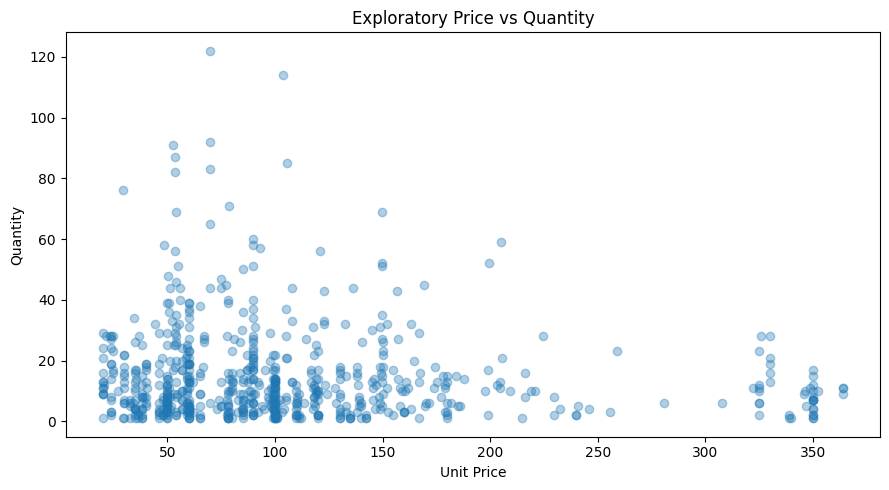

In [15]:

import matplotlib.pyplot as plt

# Positive price and quantity records for exploratory analysis
eda_df = df.loc[
    df["unit_price"].gt(0) &
    df["qty"].gt(0),
    ["product_id", "unit_price", "qty"]
].dropna()

print("Valid observations:", len(eda_df))
print("Products:", eda_df["product_id"].nunique())

# Overall relationship
print(
    "Price-quantity correlation:",
    round(eda_df["unit_price"].corr(eda_df["qty"]), 4)
)

# Scatter plot: sample at most 5000 rows for readability
plot_df = eda_df.sample(
    n=min(5000, len(eda_df)),
    random_state=42
)

plt.figure(figsize=(9, 5))
plt.scatter(
    plot_df["unit_price"],
    plot_df["qty"],
    alpha=0.35
)
plt.xlabel("Unit Price")
plt.ylabel("Quantity")
plt.title("Exploratory Price vs Quantity")
plt.tight_layout()
plt.show()


<h3 style = "background-color: #111; padding: 5px; font: bold 35px Times New Roman; color: blue";  align = "left">
    Checking Product-level data quality and demand variation</h3>

## 🔹 Step 16: Product-Level Diagnostics for Demand Variation

**📌 Methodology:** Build a diagnostics table per product: observations, distinct prices and quantities, min/max/mean of price and quantity, and price range as a percentage of the mean price.

**🔍 Important Findings:**
- Best price variation: `watches1` (17 observations, 17 distinct prices, price range about 68% of the mean), `watches2` (15/15), `watches6` (14/14), `computers4` (13 distinct).
- Some products have narrow ranges (e.g. `watches5` about 14%, `bed2` about 18%).

**💼 Business Decision:** Prioritise products with rich price history (watches, computers4, garden3, computers1) as candidates for elasticity work and pricing experiments.

In [16]:

# Product-level diagnostic table

product_diagnostics = (
    df.groupby("product_id")
      .agg(
          observations=("unit_price", "count"),
          unique_prices=("unit_price", "nunique"),
          unique_quantities=("qty", "nunique"),
          min_price=("unit_price", "min"),
          max_price=("unit_price", "max"),
          mean_price=("unit_price", "mean"),
          mean_qty=("qty", "mean"),
          min_qty=("qty", "min"),
          max_qty=("qty", "max"),
          missing_price=("unit_price", lambda x: x.isna().sum()),
          missing_qty=("qty", lambda x: x.isna().sum())
      )
      .reset_index()
)

product_diagnostics["price_range"] = (
    product_diagnostics["max_price"]
    - product_diagnostics["min_price"]
)

product_diagnostics["price_range_pct"] = (
    product_diagnostics["price_range"]
    / product_diagnostics["mean_price"] * 100
)

display(
    product_diagnostics.sort_values(
        ["unique_prices", "observations"],
        ascending=False
    ).head(15).round(3)
)


,product_id,observations,unique_prices,unique_quantities,min_price,max_price,mean_price,mean_qty,min_qty,max_qty,missing_price,missing_qty,price_range,price_range_pct
44,watches1,17,17,12,132.531,255.610,180.627,11.412,2,32,0,0,123.079,68.140
45,watches2,15,15,11,118.132,171.792,144.785,9.733,1,26,0,0,53.660,37.062
49,watches6,14,14,11,103.793,163.000,132.530,23.071,1,114,0,0,59.207,44.675
8,computers4,18,13,16,114.491,159.990,141.576,18.944,3,56,0,0,45.499,32.137
25,garden3,18,11,12,89.990,123.332,105.375,7.833,1,21,0,0,33.342,31.641
5,computers1,15,11,10,66.342,109.900,92.482,9.267,1,31,0,0,43.558,47.099
43,perfumery2,13,11,10,116.907,142.500,123.823,8.154,1,17,0,0,25.593,20.669
50,watches7,12,11,10,169.349,348.800,305.690,10.250,1,45,0,0,179.451,58.703
48,watches5,10,10,8,199.000,229.900,213.897,14.300,8,28,0,0,30.900,14.446
22,garden1,18,9,10,89.990,127.727,105.764,8.222,1,28,0,0,37.737,35.680


<h3 style = "background-color: #111; padding: 5px; font: bold 35px Times New Roman; color: blue";  align = "left">
    Checking the relationship between price and quantity of the same product</h3>

## 🔹 Step 17: Within-Product Price-Quantity Correlation

**📌 Methodology:** For each product compute the correlation between price and quantity using `safe_corr`, which returns NaN when there are fewer than 5 points or no variation.

**🔍 Important Findings:**
- Most products are negative, which is the expected demand behaviour: e.g. `bed4` -0.91 (only 3 distinct prices), `watches7` -0.77, `consoles1` -0.76, `watches8` -0.72, `bed1` -0.71.
- Several products are **positive**, e.g. `health3` +0.95, `health6` +0.73, `garden2` +0.58, `bed2` +0.47, which is counter-intuitive and points to confounding (growth, promotions, seasonality).
- `health1` and `health4` return NaN because their price never changes.

**💼 Business Decision:** Do not apply a blanket 'cut price to sell more' rule. Demand response differs strongly by product, and weak-evidence results (such as `bed4` with 3 prices) should not drive decisions.

In [17]:

def safe_corr(group):
    data = group[["unit_price", "qty"]].dropna()

    if len(data) < 5:
        return np.nan

    if data["unit_price"].nunique() < 2:
        return np.nan

    if data["qty"].nunique() < 2:
        return np.nan

    return data["unit_price"].corr(data["qty"])

product_corr = (
    df.groupby("product_id")
      .apply(safe_corr, include_groups=False)
      .rename("price_qty_correlation")
      .reset_index()
)

product_corr = product_corr.merge(
    product_diagnostics[
        ["product_id", "observations", "unique_prices"]
    ],
    on="product_id",
    how="left"
)

display(
    product_corr.sort_values(
        "price_qty_correlation"
    ).round(4)
)


,product_id,price_qty_correlation,observations,unique_prices
3,bed4,-0.9051,10,3
50,watches7,-0.7736,12,11
11,consoles1,-0.7624,12,6
51,watches8,-0.7155,10,9
0,bed1,-0.7123,16,4
43,perfumery2,-0.6726,13,11
19,furniture2,-0.6473,13,5
44,watches1,-0.5936,17,17
49,watches6,-0.5627,14,14
22,garden1,-0.5215,18,9


<h3 style = "background-color: #111; padding: 5px; font: bold 35px Times New Roman; color: blue";  align = "left">
    Varifying the availablity of more than one records at a month of each product. <br> identifying the relationship between unit price and total price and the time period of the datasets</h3>

## 🔹 Step 18: Checking Data Grain and Sales Consistency

**📌 Methodology:** Count rows per product-month, compare `total_price` with `qty x unit_price`, and review date coverage and sample size per product.

**🔍 Important Findings:**
- **676 unique product-month combinations, none duplicated**, so there is exactly one row per product per month.
- `total_price` differs from `qty x unit_price` by an average of only 1.23, with 79 rows differing by more than 0.01 (these numbers do not depend on dates).
- Date coverage now uses the corrected parsing from the audit cell, so after re-running it should show 20 unique monthly dates from 2017-01-01 to 2018-08-01.
- Outputs were cleared because the date part of the old output was wrong; re-run to refresh.

**💼 Business Decision:** The grain is clean (product-month), and the small sales mismatch is acceptable for elasticity modelling.

In [18]:

# 1. Check whether each product-month has one or multiple rows
key_cols = ["product_id", "month_year"]

product_month_counts = (
    df.groupby(key_cols, dropna=False)
      .size()
      .reset_index(name="rows_per_product_month")
)

print("Unique product-month combinations:", len(product_month_counts))
print(
    "Product-month combinations with multiple rows:",
    (product_month_counts["rows_per_product_month"] > 1).sum()
)

display(
    product_month_counts.query("rows_per_product_month > 1").head(10)
)

# 2. Check total_price against qty * unit_price
check_df = df[
    ["qty", "unit_price", "total_price"]
].dropna().copy()

check_df["calculated_sales"] = (
    check_df["qty"] * check_df["unit_price"]
)

check_df["sales_difference"] = (
    check_df["total_price"] - check_df["calculated_sales"]
)

print("\nTotal price consistency:")
print(
    "Mean absolute difference:",
    round(check_df["sales_difference"].abs().mean(), 4)
)
print(
    "Rows with difference > 0.01:",
    (check_df["sales_difference"].abs() > 0.01).sum()
)

display(check_df.head(10))

# 3. Check date coverage
print("\nDate coverage:")
print("Start:", df["month_year"].min())
print("End:", df["month_year"].max())
print("Unique dates:", df["month_year"].nunique())

# 4. Check product-level sample size
print("\nObservations per product:")
display(
    df.groupby("product_id")
      .agg(
          observations=("qty", "count"),
          unique_prices=("unit_price", "nunique"),
          unique_months=("month_year", "nunique")
      )
      .sort_values("observations", ascending=False)
      .head(15)
)


Unique product-month combinations: 676
Product-month combinations with multiple rows: 0


,product_id,month_year,rows_per_product_month



Total price consistency:
Mean absolute difference: 1.2343
Rows with difference > 0.01: 79


,qty,unit_price,total_price,calculated_sales,sales_difference
0,1,45.950000,45.95,45.95,0.000000e+00
1,3,45.950000,137.85,137.85,-2.842171e-14
2,6,45.950000,275.70,275.70,-5.684342e-14
3,4,45.950000,183.80,183.80,0.000000e+00
4,2,45.950000,91.90,91.90,0.000000e+00
5,3,45.950000,137.85,137.85,-2.842171e-14
6,11,40.531818,445.85,445.85,2.000002e-08
7,6,39.990000,239.94,239.94,0.000000e+00
8,19,39.990000,759.81,759.81,-1.136868e-13
9,18,39.990000,719.82,719.82,0.000000e+00



Date coverage:
Start: 2017-01-01 00:00:00
End: 2018-08-01 00:00:00
Unique dates: 20

Observations per product:


,observations,unique_prices,unique_months
product_id,,,
health5,20,4,20
health7,20,4,20
bed2,19,8,19
computers4,18,13,18
garden3,18,11,18
garden1,18,9,18
health9,18,3,18
health8,17,4,17
garden9,17,7,17


<h3 style = "background-color: #111; padding: 5px; font: bold 35px Times New Roman; color: blue";  align = "left">
    Auditing the Date and sales discrepancies</h3>

## 🔹 Step 19: Auditing Dates and Sales Discrepancies

**📌 Methodology:** List all observed dates, test whether they fall on the first of the month, inspect the largest sales mismatches, re-check positivity and search for cost/profit columns.

**🔍 Important Findings:**
- The old output showed only **50 of 676** dates on day 1, which exposed the day/month swap. With the parsing fix, **all 676** should fall on the first of the month after re-running.
- 79 sales mismatches in total; the largest is about +147.6 on roughly 5,300 of sales (small in relative terms).
- No zero, negative or missing sales values. **No cost or profit column** exists.
- Outputs were cleared (they showed the pre-fix dates); re-run to refresh.

**💼 Business Decision:** The absence of cost data is formally confirmed, so profit analysis must rely on explicit assumptions.

In [19]:

# A. Inspect all observed dates
print("Sorted date values:")
display(
    df["month_year"]
      .dropna()
      .drop_duplicates()
      .sort_values()
      .to_frame()
      .reset_index(drop=True)
)

# B. Check whether dates fall on the first day of each month
valid_dates = df["month_year"].dropna()

print(
    "\nDates on first day of month:",
    (valid_dates.dt.day == 1).sum(),
    "out of", len(valid_dates)
)

# C. Inspect sales mismatches
audit = df[
    ["product_id", "month_year", "qty",
     "unit_price", "total_price", "freight_price"]
].copy()

audit["calculated_sales"] = audit["qty"] * audit["unit_price"]
audit["sales_difference"] = (
    audit["total_price"] - audit["calculated_sales"]
)

mismatches = audit.loc[
    audit["sales_difference"].abs() > 0.01
].sort_values("sales_difference", key=abs, ascending=False)

print("\nMismatch count:", len(mismatches))
display(mismatches.head(15))

# D. Check whether price, quantity and sales are positive
for col in ["qty", "unit_price", "total_price"]:
    print(
        f"{col}: zero={(df[col] == 0).sum()}, "
        f"negative={(df[col] < 0).sum()}, "
        f"missing={df[col].isna().sum()}"
    )

# E. Check if any cost-related columns exist
cost_candidates = [
    col for col in df.columns
    if any(term in col.lower()
           for term in ["cost", "cogs", "expense", "margin", "profit"])
]

print("\nPotential cost/profit columns:", cost_candidates)


Sorted date values:


,month_year
0,2017-01-01
1,2017-02-01
2,2017-03-01
3,2017-04-01
4,2017-05-01
5,2017-06-01
6,2017-07-01
7,2017-08-01
8,2017-09-01
9,2017-10-01



Dates on first day of month: 676 out of 676

Mismatch count: 79


,product_id,month_year,qty,unit_price,total_price,freight_price,calculated_sales,sales_difference
152,computers5,2018-01-01,57,93.094894,5453.96,12.239123,5306.408936,147.551064
270,watches6,2017-09-01,18,148.778571,2762.50,14.041111,2678.014285,84.485715
196,garden6,2017-12-01,51,55.100000,2881.60,15.759608,2810.100000,71.500000
613,computers3,2017-05-01,15,178.057143,2715.70,18.754667,2670.857143,44.842856
164,garden10,2017-11-01,87,53.648281,4712.19,16.075862,4667.400469,44.789531
382,watches5,2017-11-01,12,203.290909,2395.20,19.795000,2439.490909,-44.290909
612,watches7,2018-07-01,45,169.349318,7651.27,17.953556,7620.719319,30.550681
257,garden9,2017-11-01,82,53.379104,4397.70,17.807805,4377.086567,20.613433
276,watches6,2018-04-01,85,105.648625,8961.49,2.181647,8980.133125,-18.643125
556,garden1,2017-09-01,7,102.500000,735.00,30.040000,717.500000,17.500000


qty: zero=0, negative=0, missing=0
unit_price: zero=0, negative=0, missing=0
total_price: zero=0, negative=0, missing=0

Potential cost/profit columns: []


<h3 style = "background-color: #111; padding: 5px; font: bold 35px Times New Roman; color: blue";  align = "left">
    Again the raw data investigation</h3>

## 🔹 Step 20: Investigating the Raw Dates and the Sales Formula

**📌 Methodology:** Reload the CSV without date parsing, inspect raw date strings and their counts, and test two formulas: `qty x price` versus `qty x price + freight`.

**🔍 Important Findings:**
- Raw dates are **day-first (DD-MM-YYYY)**, e.g. `01-05-2017` is 1 May 2017. They cover 20 distinct months from Jan 2017 to Aug 2018. This investigation is what led to the fix now applied in the data-quality audit cell.
- Rows per month grow from 2 (Jan 2017) to about 50 (Mar 2018).
- `total_price` matches `qty x unit_price` (mean absolute difference 1.23) much better than with freight added (21.18), so **`total_price` excludes freight**.

**💼 Business Decision:** Revenue should be defined as `total_price` (product revenue). Freight is a separate cost that must be included when real profit is calculated.

In [20]:

# Reload the original CSV without automatic date parsing
df_raw = pd.read_csv(r"C:\Users\mdnay\Desktop\My_Code\Projects\price-elasticity-profit-optimization\data\raw\retail_price.csv")

print("Raw month_year values:")
print(df_raw["month_year"].head(15).tolist())

print("\nDistinct raw date values:")
print(
    df_raw["month_year"]
    .drop_duplicates()
    .sort_values()
    .tolist()
)

print("\nRaw date value counts:")
display(
    df_raw["month_year"]
    .value_counts()
    .sort_index()
    .to_frame("row_count")
)

# Check sales formula alternatives
audit = df_raw[
    ["qty", "unit_price", "total_price", "freight_price"]
].apply(pd.to_numeric, errors="coerce").dropna()

audit["qty_times_price"] = audit["qty"] * audit["unit_price"]

audit["difference_excluding_freight"] = (
    audit["total_price"] - audit["qty_times_price"]
)

audit["difference_including_freight"] = (
    audit["total_price"]
    - audit["qty_times_price"]
    - audit["freight_price"]
)

print("\nMean absolute difference: qty × unit_price")
print(audit["difference_excluding_freight"].abs().mean())

print("\nMean absolute difference: qty × unit_price + freight")
print(audit["difference_including_freight"].abs().mean())

display(
    audit.loc[
        audit["difference_excluding_freight"].abs() > 0.01
    ].head(10)
)


Raw month_year values:
['01-05-2017', '01-06-2017', '01-07-2017', '01-08-2017', '01-09-2017', '01-10-2017', '01-11-2017', '01-12-2017', '01-01-2018', '01-02-2018', '01-03-2018', '01-04-2018', '01-05-2018', '01-06-2018', '01-07-2018']

Distinct raw date values:
['01-01-2017', '01-01-2018', '01-02-2017', '01-02-2018', '01-03-2017', '01-03-2018', '01-04-2017', '01-04-2018', '01-05-2017', '01-05-2018', '01-06-2017', '01-06-2018', '01-07-2017', '01-07-2018', '01-08-2017', '01-08-2018', '01-09-2017', '01-10-2017', '01-11-2017', '01-12-2017']

Raw date value counts:


,row_count
month_year,
01-01-2017,2
01-01-2018,48
01-02-2017,9
01-02-2018,49
01-03-2017,13
01-03-2018,50
01-04-2017,15
01-04-2018,48
01-05-2017,20



Mean absolute difference: qty × unit_price
1.2342914014793187

Mean absolute difference: qty × unit_price + freight
21.178732038761833


,qty,unit_price,total_price,freight_price,qty_times_price,difference_excluding_freight,difference_including_freight
18,20,97.588235,1956.00,39.897500,1951.764706,4.235294,-35.662206
21,7,97.333333,683.00,39.500000,681.333333,1.666667,-37.833333
48,20,51.322222,1043.60,16.016000,1026.444444,17.155556,1.139556
49,10,56.977778,571.80,18.103000,569.777778,2.022222,-16.080778
54,9,52.900000,477.10,16.460000,476.100000,1.000000,-15.460000
64,28,23.397407,651.72,14.276786,655.127407,-3.407407,-17.684193
140,69,53.785714,3711.70,18.275507,3711.214286,0.485714,-17.789793
141,44,55.750000,2468.60,17.267273,2453.000000,15.600000,-1.667273
143,48,50.357143,2411.20,18.281875,2417.142857,-5.942857,-24.224732
146,25,53.057895,1319.50,12.980000,1326.447369,-6.947369,-19.927369


<h3 style = "background-color: #111; padding: 5px; font: bold 35px Times New Roman; color: blue";  align = "left">
    Verifying the monthly coverage after date format reformed</h3>

## 🔹 Step 21: Re-parsing Dates and Verifying Monthly Coverage

**📌 Methodology:** Reload the data and parse `month_year` with the explicit format `%d-%m-%Y`; then count rows and unique products per month.

**🔍 Important Findings:**
- 0 invalid dates; correct range **2017-01-01 to 2018-08-01** with 20 consecutive monthly dates (consistent with the fix now applied earlier in the notebook).
- Product coverage grows from 2 products (Jan 2017) to 50 (Mar 2018), then falls to 38 (Aug 2018).
- This cell reloads and re-parses the data, so it also acts as a clean reset for all later modelling.

**💼 Business Decision:** The product assortment expanded over time, so early periods are thin and sales growth partly reflects catalogue growth. Models must account for time trend, or price effects will be overstated.

In [21]:
import pandas as pd

# Reload the original dataset
df = pd.read_csv(r"C:\Users\mdnay\Desktop\My_Code\Projects\price-elasticity-profit-optimization\data\raw\retail_price.csv")

# Parse dates explicitly as DD-MM-YYYY
df["month_year"] = pd.to_datetime(
    df["month_year"],
    format="%d-%m-%Y",
    errors="coerce"
)

# Check date parsing
print("Invalid dates:", df["month_year"].isna().sum())
print("Date range:", df["month_year"].min(), "to", df["month_year"].max())
print("Unique dates:", df["month_year"].nunique())

# Monthly observation counts
monthly_counts = (
    df.groupby("month_year")
      .size()
      .rename("row_count")
      .reset_index()
      .sort_values("month_year")
)

display(monthly_counts)

# Product coverage per month
product_coverage = (
    df.groupby("month_year")["product_id"]
      .nunique()
      .rename("unique_products")
      .reset_index()
      .sort_values("month_year")
)

display(product_coverage)

Invalid dates: 0
Date range: 2017-01-01 00:00:00 to 2018-08-01 00:00:00
Unique dates: 20


,month_year,row_count
0,2017-01-01,2
1,2017-02-01,9
2,2017-03-01,13
3,2017-04-01,15
4,2017-05-01,20
5,2017-06-01,25
6,2017-07-01,33
7,2017-08-01,37
8,2017-09-01,36
9,2017-10-01,43


,month_year,unique_products
0,2017-01-01,2
1,2017-02-01,9
2,2017-03-01,13
3,2017-04-01,15
4,2017-05-01,20
5,2017-06-01,25
6,2017-07-01,33
7,2017-08-01,37
8,2017-09-01,36
9,2017-10-01,43


<h3 style = "background-color: #111; padding: 5px; font: bold 35px Times New Roman; color: blue";  align = "left">
    Selecting the perfect product for elasticity estimation</h3>

## 🔹 Step 22: Selecting Products Suitable for Elasticity Estimation

**📌 Methodology:** Aggregate per product and apply minimum data rules: at least 12 observations, at least 5 distinct prices, and positive price and quantity.

**🔍 Important Findings:**
- Of 52 products, **20** pass the screening; the largest samples are `bed2` (19), `computers4` (18), `garden3` (18), `garden1` (18), `watches1` (17).
- Many garden products share the same price band (49.90 to 59.90), which suggests a fixed pricing rule or standard price points.

**💼 Business Decision:** Elasticity-based recommendations will only be considered for the 20 eligible products. The remaining 32 lack enough data and should be handled with testing, not modelling.

In [22]:
# Ensure the key columns are numeric
for col in ["qty", "unit_price", "total_price"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Product-level data quality and variation
product_summary = (
    df.groupby("product_id")
      .agg(
          observations=("month_year", "count"),
          months_observed=("month_year", "nunique"),
          unique_prices=("unit_price", "nunique"),
          min_price=("unit_price", "min"),
          max_price=("unit_price", "max"),
          mean_price=("unit_price", "mean"),
          min_qty=("qty", "min"),
          max_qty=("qty", "max"),
          mean_qty=("qty", "mean")
      )
      .reset_index()
)

# Calculate percentage price range
product_summary["price_range_pct"] = (
    (product_summary["max_price"] - product_summary["min_price"])
    / product_summary["mean_price"] * 100
)

# Initial eligibility criteria for exploration, not final statistical proof
eligible_products = product_summary[
    (product_summary["observations"] >= 12)
    & (product_summary["unique_prices"] >= 5)
    & (product_summary["min_price"] > 0)
    & (product_summary["min_qty"] > 0)
].sort_values(
    ["observations", "unique_prices"],
    ascending=False
)

print("Total unique products:", df["product_id"].nunique())
print("Initially eligible products:", len(eligible_products))

display(
    eligible_products[
        [
            "product_id",
            "observations",
            "months_observed",
            "unique_prices",
            "min_price",
            "max_price",
            "mean_price",
            "mean_qty",
            "price_range_pct"
        ]
    ].round(2).head(20)
)

Total unique products: 52
Initially eligible products: 20


,product_id,observations,months_observed,unique_prices,min_price,max_price,mean_price,mean_qty,price_range_pct
1,bed2,19,19,8,74.00,89.90,86.77,25.63,18.32
8,computers4,18,18,13,114.49,159.99,141.58,18.94,32.14
25,garden3,18,18,11,89.99,123.33,105.37,7.83,31.64
22,garden1,18,18,9,89.99,127.73,105.76,8.22,35.68
44,watches1,17,17,17,132.53,255.61,180.63,11.41,68.14
31,garden9,17,17,7,49.90,59.90,55.26,21.94,18.10
24,garden2,17,17,5,49.90,59.90,54.83,7.47,18.24
28,garden6,16,16,8,49.90,59.90,54.89,30.25,18.22
23,garden10,16,16,7,49.90,59.90,55.03,24.44,18.17
29,garden7,16,16,7,49.90,59.90,54.96,7.19,18.19


<h3 style = "background-color: #111; padding: 5px; font: bold 35px Times New Roman; color: blue";  align = "left">
    Exploratory Data Analysis</h3>

<h3 style = "background-color: #111; padding: 5px; font: bold 35px Times New Roman; color: blue";  align = "left">
    Checking the price and quantity trend of computers4</h3>

## 🔹 Step 23: Exploring Price and Quantity Trends for `computers4`

**📌 Methodology:** Take one well-observed product, plot price and quantity over time, draw a price-vs-quantity regression plot and inspect the correlation matrix with competitor prices, customers and lag price.

**🔍 Important Findings:**
- 18 observations from Feb 2017 to Aug 2018. Price fell from about 160 to about 114 to 120 while quantity grew from 3 to a peak of 56 (Apr 2018), then dropped to 9-10 even though price stayed at 119.99.
- Price-quantity correlation is only **-0.314**, while quantity is strongly linked to `customers` (**+0.814**).
- `comp_1` is identical to `unit_price` (correlation 1.0), so it is not an independent competitor signal here; `product_score` is constant.

**💼 Business Decision:** Demand is driven largely by customer traffic, not price alone. Pricing decisions for this product should be tested while controlling for traffic and seasonality.

Product: computers4
Number of observations: 18
Date range: 2017-02-01 00:00:00 to 2018-08-01 00:00:00


C:\Users\mdnay\AppData\Local\Temp\ipykernel_9424\2292377577.py:22: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(product_df[columns_to_inspect].round(3))


,month_year,qty,unit_price,total_price,freight_price,comp_1,comp_2,comp_3,product_score,customers,lag_price
583,2017-02-01,3,159.990,479.97,33.400,159.990,159.990,159.990,4.2,3,159.940
584,2017-03-01,3,159.990,479.97,33.400,159.990,159.990,159.990,4.2,3,159.990
585,2017-04-01,5,139.990,699.95,35.122,139.990,139.990,139.990,4.2,5,159.990
586,2017-06-01,3,159.990,479.97,42.033,159.990,159.990,159.990,4.2,15,159.940
587,2017-07-01,6,139.990,839.94,48.108,139.990,139.990,139.990,4.2,17,159.990
588,2017-08-01,7,145.704,1019.93,36.460,145.704,145.704,145.704,4.2,15,139.990
589,2017-09-01,11,151.990,1679.89,43.723,151.990,151.990,151.990,4.2,15,145.704
590,2017-10-01,17,154.696,2629.83,43.881,154.696,154.696,154.696,4.2,31,151.990
591,2017-11-01,18,149.990,2699.82,42.517,149.990,149.990,109.900,4.2,36,154.696
592,2017-12-01,23,149.990,3449.77,38.570,149.990,149.990,109.900,4.2,35,149.990


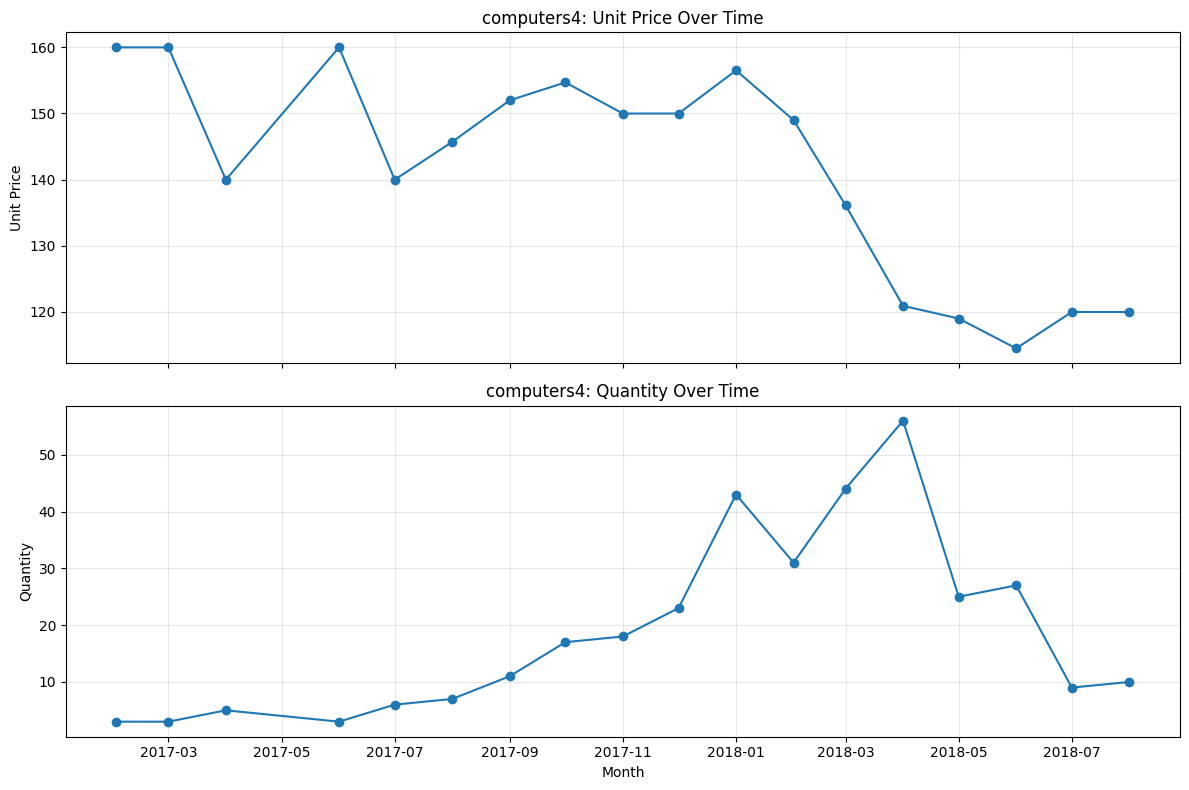

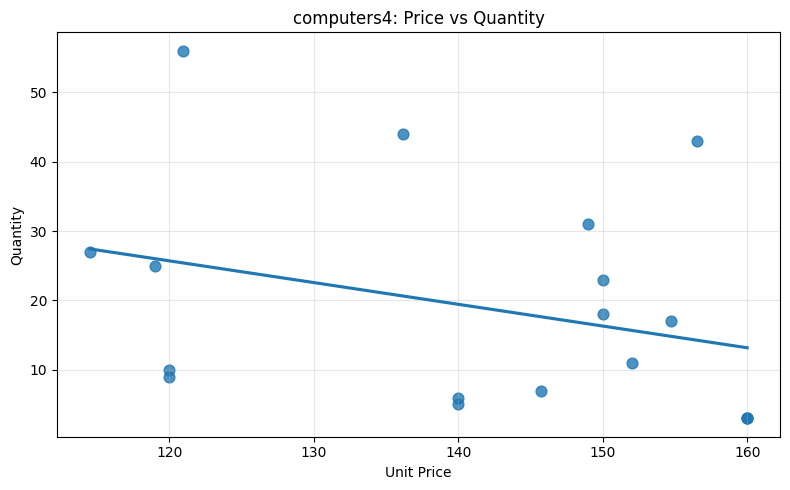

,qty,unit_price,comp_1,comp_2,comp_3,product_score,customers,lag_price
qty,1.000,-0.314,-0.314,-0.118,-0.673,NaN,0.814,-0.198
unit_price,-0.314,1.000,1.000,0.434,0.749,NaN,-0.154,0.857
comp_1,-0.314,1.000,1.000,0.434,0.749,NaN,-0.154,0.857
comp_2,-0.118,0.434,0.434,1.000,0.297,NaN,-0.101,0.141
comp_3,-0.673,0.749,0.749,0.297,1.000,NaN,-0.669,0.671
product_score,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customers,0.814,-0.154,-0.154,-0.101,-0.669,NaN,1.000,-0.083
lag_price,-0.198,0.857,0.857,0.141,0.671,NaN,-0.083,1.000


In [23]:
# Select one product
product_name = "computers4"

product_df = (
    df[df["product_id"] == product_name]
    .sort_values("month_year")
    .copy()
)

print(f"Product: {product_name}")
print("Number of observations:", len(product_df))
print("Date range:", product_df["month_year"].min(), "to",
      product_df["month_year"].max())

# Inspect relevant records
columns_to_inspect = [
    "month_year", "qty", "unit_price", "total_price",
    "freight_price", "comp_1", "comp_2", "comp_3",
    "product_score", "customers", "lag_price"
]

display(product_df[columns_to_inspect].round(3))

# Plot price and quantity over time
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(
    product_df["month_year"],
    product_df["unit_price"],
    marker="o"
)
axes[0].set_title(f"{product_name}: Unit Price Over Time")
axes[0].set_ylabel("Unit Price")
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    product_df["month_year"],
    product_df["qty"],
    marker="o"
)
axes[1].set_title(f"{product_name}: Quantity Over Time")
axes[1].set_ylabel("Quantity")
axes[1].set_xlabel("Month")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Price-quantity scatter plot
plt.figure(figsize=(8, 5))
sns.regplot(
    data=product_df,
    x="unit_price",
    y="qty",
    ci=None,
    scatter_kws={"s": 60}
)
plt.title(f"{product_name}: Price vs Quantity")
plt.xlabel("Unit Price")
plt.ylabel("Quantity")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Correlation inspection
corr_columns = [
    "qty", "unit_price", "comp_1", "comp_2",
    "comp_3", "product_score", "customers", "lag_price"
]

corr_columns = [
    c for c in corr_columns
    if c in product_df.columns
    and pd.api.types.is_numeric_dtype(product_df[c])
]

display(
    product_df[corr_columns]
    .corr()
    .round(3)
)

<h3 style = "background-color: #111; padding: 5px; font: bold 35px Times New Roman; color: blue";  align = "left">
    Data quality check and baseline elasticity model</h3>

$$
\ln(Q_t)=\beta_0+\beta_1\ln(P_t)+\epsilon_t
$$

## 🔹 Step 24: Baseline Log-Log Elasticity Model for `computers4`

**📌 Methodology:** Fit `ln(Q) = b0 + b1 ln(P)` by OLS with HC3 robust standard errors. The coefficient `b1` is the price elasticity.

**🔍 Important Findings:**
- Estimated elasticity **-3.217**, 95% confidence interval **[-6.959, 0.524]**, p = 0.092, R-squared = 0.153, n = 18.
- The confidence interval includes zero, so the effect is not statistically distinguishable from no effect.
- Durbin-Watson = 0.246, a strong sign of autocorrelated residuals (time structure left unmodelled).

**💼 Business Decision:** Do not change `computers4` prices based on this model. The evidence is too weak and the model misses time dynamics.

In [24]:
import statsmodels.api as sm

# Re-check the selected product
model_df = product_df[
    ["month_year", "qty", "unit_price", "customers"]
].copy()

# Convert numeric columns safely
for col in ["qty", "unit_price", "customers"]:
    model_df[col] = pd.to_numeric(model_df[col], errors="coerce")

print("Data types:")
print(model_df.dtypes)

print("\nMissing values:")
print(model_df.isna().sum())

print("\nUnique values:")
print(model_df.nunique())

# Keep only valid positive values for log transformation
model_df = model_df.dropna(
    subset=["qty", "unit_price"]
).copy()

model_df = model_df[
    (model_df["qty"] > 0)
    & (model_df["unit_price"] > 0)
].copy()

model_df["log_qty"] = np.log(model_df["qty"])
model_df["log_price"] = np.log(model_df["unit_price"])

# Baseline log-log OLS
X = sm.add_constant(model_df["log_price"])
y = model_df["log_qty"]

baseline_model = sm.OLS(y, X).fit(cov_type="HC3")

print("\nBaseline log-log regression:")
print(baseline_model.summary())

elasticity = baseline_model.params["log_price"]
ci_low, ci_high = baseline_model.conf_int().loc["log_price"]

print(f"\nEstimated price elasticity: {elasticity:.3f}")
print(f"95% confidence interval: [{ci_low:.3f}, {ci_high:.3f}]")
print(f"R-squared: {baseline_model.rsquared:.3f}")

Data types:
month_year    datetime64[us]
qty                    int64
unit_price           float64
customers              int64
dtype: object

Missing values:
month_year    0
qty           0
unit_price    0
customers     0
dtype: int64

Unique values:
month_year    18
qty           16
unit_price    13
customers     15
dtype: int64

Baseline log-log regression:
                            OLS Regression Results                            
Dep. Variable:                log_qty   R-squared:                       0.153
Model:                            OLS   Adj. R-squared:                  0.100
Method:                 Least Squares   F-statistic:                     2.840
Date:                Mon, 26 Oct 2026   Prob (F-statistic):              0.111
Time:                        15:49:44   Log-Likelihood:                -22.900
No. Observations:                  18   AIC:                             49.80
Df Residuals:                      16   BIC:                             51.58
Df Mo

## 🔹 Step 25: Comparing Price-Only vs Price + Time-Trend Models

**📌 Methodology:** Fit Model A (log price) and Model B (log price + linear time trend) and compare elasticity, p-value, R-squared and AIC.

**🔍 Important Findings:**
- Price-only: elasticity -3.217 (p = 0.092), R-squared 0.153, AIC 49.8.
- With time trend: elasticity **+3.793** (p = 0.055), R-squared 0.574, AIC 39.4.
- Adding the trend improves fit sharply but **flips the sign** to an economically implausible positive elasticity.

**💼 Business Decision:** The `computers4` estimate is unstable and cannot support price decisions. A positive elasticity signals that trend and price are tangled together.

In [25]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

trend_df = product_df[
    ["month_year", "qty", "unit_price"]
].copy()

for col in ["qty", "unit_price"]:
    trend_df[col] = pd.to_numeric(
        trend_df[col], errors="coerce"
    )

trend_df = trend_df.dropna(
    subset=["month_year", "qty", "unit_price"]
).copy()

trend_df = trend_df[
    (trend_df["qty"] > 0)
    & (trend_df["unit_price"] > 0)
].sort_values("month_year").reset_index(drop=True)

trend_df["log_qty"] = np.log(trend_df["qty"])
trend_df["log_price"] = np.log(trend_df["unit_price"])

# One step per observed month; missing months are not imputed
trend_df["time_trend"] = np.arange(len(trend_df))

# Model A: price only
X1 = sm.add_constant(trend_df[["log_price"]])
model_a = sm.OLS(
    trend_df["log_qty"], X1
).fit(cov_type="HC3")

# Model B: price + linear time trend
X2 = sm.add_constant(
    trend_df[["log_price", "time_trend"]]
)
model_b = sm.OLS(
    trend_df["log_qty"], X2
).fit(cov_type="HC3")

comparison = pd.DataFrame({
    "model": ["Price only", "Price + time trend"],
    "price_elasticity": [
        model_a.params["log_price"],
        model_b.params["log_price"]
    ],
    "price_p_value": [
        model_a.pvalues["log_price"],
        model_b.pvalues["log_price"]
    ],
    "r_squared": [
        model_a.rsquared,
        model_b.rsquared
    ],
    "AIC": [
        model_a.aic,
        model_b.aic
    ]
})

display(comparison.round(4))

print("\nPrice-only model:")
print(model_a.summary())

print("\nPrice + time-trend model:")
print(model_b.summary())

,model,price_elasticity,price_p_value,r_squared,AIC
0,Price only,-3.2173,0.0919,0.1528,49.8010
1,Price + time trend,3.7927,0.0553,0.5737,39.4393



Price-only model:
                            OLS Regression Results                            
Dep. Variable:                log_qty   R-squared:                       0.153
Model:                            OLS   Adj. R-squared:                  0.100
Method:                 Least Squares   F-statistic:                     2.840
Date:                Mon, 26 Oct 2026   Prob (F-statistic):              0.111
Time:                        15:49:44   Log-Likelihood:                -22.900
No. Observations:                  18   AIC:                             49.80
Df Residuals:                      16   BIC:                             51.58
Df Model:                           1                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         18.4655      9.384 

## 🔹 Step 26: Diagnosing the Price-Time Relationship

**📌 Methodology:** Check how strongly price is correlated with the time index and print both model results side by side.

**🔍 Important Findings:**
- Correlation between log price and time trend = **-0.795**: price fell steadily while sales grew over the same period.
- The data cannot cleanly separate 'price effect' from 'growth over time' (collinearity).

**💼 Business Decision:** Price changes that follow a time pattern cannot prove causality. Future price changes should be made independently of the calendar (A/B tests or randomised price points).

In [26]:
# Step 22: Diagnose price-demand relationship

diagnostic_df = trend_df[
    ["month_year", "qty", "unit_price", "log_qty", "log_price", "time_trend"]
].copy()

diagnostic_df = diagnostic_df.sort_values("month_year")

print("Number of observations:", len(diagnostic_df))
print("Unique prices:", diagnostic_df["unit_price"].nunique())
print(
    "Correlation: log price vs time trend:",
    round(diagnostic_df["log_price"].corr(diagnostic_df["time_trend"]), 3)
)

display(
    diagnostic_df[
        ["month_year", "qty", "unit_price", "time_trend"]
    ].round(3)
)

# Compare the two model specifications
print("\nPrice-only model")
print("Price coefficient:", round(baseline_model.params["log_price"], 3))
print("Price p-value:", round(baseline_model.pvalues["log_price"], 4))
print("R-squared:", round(baseline_model.rsquared, 3))

print("\nPrice + time-trend model")
print("Price coefficient:", round(model_b.params["log_price"], 3))
print("Price p-value:", round(model_b.pvalues["log_price"], 4))
print("R-squared:", round(model_b.rsquared, 3))


Number of observations: 18
Unique prices: 13
Correlation: log price vs time trend: -0.795


C:\Users\mdnay\AppData\Local\Temp\ipykernel_9424\4039987346.py:19: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(3)


,month_year,qty,unit_price,time_trend
0,2017-02-01,3,159.990,0
1,2017-03-01,3,159.990,1
2,2017-04-01,5,139.990,2
3,2017-06-01,3,159.990,3
4,2017-07-01,6,139.990,4
5,2017-08-01,7,145.704,5
6,2017-09-01,11,151.990,6
7,2017-10-01,17,154.696,7
8,2017-11-01,18,149.990,8
9,2017-12-01,23,149.990,9



Price-only model
Price coefficient: -3.217
Price p-value: 0.0919
R-squared: 0.153

Price + time-trend model
Price coefficient: 3.793
Price p-value: 0.0553
R-squared: 0.574


<h3 style = "background-color: #111; padding: 5px; font: bold 35px Times New Roman; color: blue";  align = "left">
    Elasticity Estimation Across All 20 Eligible Products</h3>

## 🔹 Step 27: Elasticity Estimation Across All 20 Eligible Products

**📌 Methodology:** Loop through each eligible product, fit the price-only and price + trend models (HC3), and compare elasticities, p-values and R-squared. Flag products where the sign changes.

**🔍 Important Findings:**
- The sign **changes for 5 of 20 products** (`computers4`, `garden6`, `garden8`, `garden4`, `garden5`) when the trend is added, so those estimates are unreliable.
- Some trend-adjusted results are implausibly positive (`bed2` +8.65, `garden2` +14.75), a sign of confounding rather than real demand behaviour.
- The most convincing negative and significant results (p < 0.05) are `watches1` (-5.862), `watches2` (-6.497), `watches6` (-10.8), `perfumery2` (-8.554) and `furniture2` (-12.85).

**💼 Business Decision:** Shortlist these five products as pilot candidates. Do not apply elasticity-based pricing to the remaining products.

In [27]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

# Keep valid observations
analysis_df = df.copy()
analysis_df["month_year"] = pd.to_datetime(
    analysis_df["month_year"], errors="coerce"
)

analysis_df = analysis_df.dropna(
    subset=["product_id", "month_year", "qty", "unit_price"]
)

analysis_df = analysis_df[
    (analysis_df["qty"] > 0) &
    (analysis_df["unit_price"] > 0)
].copy()

results = []

for product_id, group in analysis_df.groupby("product_id"):
    group = group.sort_values("month_year").copy()

    # Apply minimum data requirements
    if len(group) < 12 or group["unit_price"].nunique() < 5:
        continue

    group["log_qty"] = np.log(group["qty"])
    group["log_price"] = np.log(group["unit_price"])
    group["time_trend"] = np.arange(len(group))

    # Model A: price only
    X_a = sm.add_constant(group[["log_price"]])
    model_a = sm.OLS(group["log_qty"], X_a).fit(cov_type="HC3")

    # Model B: price + linear time trend
    X_b = sm.add_constant(group[["log_price", "time_trend"]])
    model_b = sm.OLS(group["log_qty"], X_b).fit(cov_type="HC3")

    elasticity_a = model_a.params["log_price"]
    elasticity_b = model_b.params["log_price"]

    results.append({
        "product_id": product_id,
        "observations": len(group),
        "unique_prices": group["unit_price"].nunique(),
        "elasticity_price_only": elasticity_a,
        "pvalue_price_only": model_a.pvalues["log_price"],
        "r2_price_only": model_a.rsquared,
        "elasticity_with_trend": elasticity_b,
        "pvalue_with_trend": model_b.pvalues["log_price"],
        "r2_with_trend": model_b.rsquared,
        "sign_changed": np.sign(elasticity_a) != np.sign(elasticity_b)
    })

elasticity_comparison = pd.DataFrame(results)

elasticity_comparison = elasticity_comparison.sort_values(
    "observations", ascending=False
).reset_index(drop=True)

display(elasticity_comparison.round(3))

print("\nEligible products:", len(elasticity_comparison))
print(
    "Products where elasticity sign changes after adding time trend:",
    int(elasticity_comparison["sign_changed"].sum())
)

,product_id,observations,unique_prices,elasticity_price_only,pvalue_price_only,r2_price_only,elasticity_with_trend,pvalue_with_trend,r2_with_trend,sign_changed
0,bed2,19,8,5.670,0.022,0.144,8.650,0.213,0.163,False
1,computers4,18,13,-3.217,0.092,0.153,3.793,0.055,0.574,True
2,garden3,18,11,-2.543,0.282,0.089,-2.592,0.253,0.165,False
3,garden1,18,9,-4.133,0.138,0.221,-3.860,0.179,0.273,False
4,watches1,17,17,-2.735,0.000,0.360,-5.862,0.000,0.605,False
5,garden9,17,7,-2.191,0.467,0.039,-1.940,0.753,0.039,False
6,garden2,17,5,7.484,0.005,0.393,14.747,0.000,0.516,False
7,garden7,16,7,-4.839,0.078,0.224,-3.181,0.641,0.234,False
8,garden6,16,8,-1.217,0.797,0.006,3.352,0.674,0.037,True
9,garden10,16,7,-2.128,0.546,0.032,-1.620,0.792,0.032,False



Eligible products: 20
Products where elasticity sign changes after adding time trend: 5


<h3 style = "background-color: #111; padding: 5px; font: bold 35px Times New Roman; color: blue";  align = "left">
    Robustness Check with HC3 and HAC Standard Errors (Shortlisted Products)</h3>

## 🔹 Step 28: Robustness Check with HC3 and HAC Standard Errors (Shortlisted Products)

**📌 Methodology:** Re-estimate the price + trend model for the 5 candidates with HC3 (heteroscedasticity-robust) and HAC (autocorrelation-robust, 1 lag) errors, and add the Durbin-Watson statistic.

**🔍 Important Findings:**
- Coefficients are identical under both methods (only the standard errors differ), and all remain significant: `watches1` -5.862, `watches2` -6.497, `watches6` -10.8, `perfumery2` -8.554, `furniture2` -12.85 (p < 0.05).
- Durbin-Watson values of 1.74 to 2.42 show that residual autocorrelation is largely handled by the trend.
- Price is strongly negatively correlated with time for four products (-0.72 to -0.89), but positively (+0.55) for `furniture2`, so its negative elasticity is less likely to be a pure trend artefact.

**💼 Business Decision:** These five are the only products with reasonably robust evidence, and the only ones that should be considered for controlled price tests.

In [28]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

candidate_products = [
    "watches1",
    "watches2",
    "watches6",
    "perfumery2",
    "furniture2"
]

robustness_results = []

for product_id in candidate_products:
    g = df.loc[df["product_id"] == product_id].copy()

    g["month_year"] = pd.to_datetime(
        g["month_year"], errors="coerce"
    )
    g = g.dropna(
        subset=["month_year", "qty", "unit_price"]
    )

    g = g[
        (g["qty"] > 0) &
        (g["unit_price"] > 0)
    ].sort_values("month_year").copy()

    if len(g) < 12 or g["unit_price"].nunique() < 5:
        continue

    g["log_qty"] = np.log(g["qty"])
    g["log_price"] = np.log(g["unit_price"])
    g["time_trend"] = np.arange(len(g))

    X = sm.add_constant(g[["log_price", "time_trend"]])
    model_hc3 = sm.OLS(g["log_qty"], X).fit(cov_type="HC3")
    model_hac = sm.OLS(g["log_qty"], X).fit(
        cov_type="HAC",
        cov_kwds={"maxlags": 1}
    )

    robustness_results.append({
        "product_id": product_id,
        "n": len(g),
        "price_time_corr": g["log_price"].corr(g["time_trend"]),
        "elasticity_HC3": model_hc3.params["log_price"],
        "pvalue_HC3": model_hc3.pvalues["log_price"],
        "elasticity_HAC": model_hac.params["log_price"],
        "pvalue_HAC": model_hac.pvalues["log_price"],
        "durbin_watson": sm.stats.stattools.durbin_watson(
            model_hc3.resid
        ),
        "r_squared": model_hc3.rsquared
    })

robustness_df = pd.DataFrame(robustness_results)

display(
    robustness_df.round(3)
    .sort_values("product_id")
    .reset_index(drop=True)
)

,product_id,n,price_time_corr,elasticity_HC3,pvalue_HC3,elasticity_HAC,pvalue_HAC,durbin_watson,r_squared
0,furniture2,13,0.552,-12.850,0.001,-12.850,0.000,1.741,0.760
1,perfumery2,13,-0.722,-8.554,0.001,-8.554,0.000,2.417,0.781
2,watches1,17,-0.810,-5.862,0.000,-5.862,0.000,2.221,0.605
3,watches2,15,-0.747,-6.497,0.008,-6.497,0.001,2.161,0.425
4,watches6,14,-0.889,-10.800,0.038,-10.800,0.007,1.985,0.330


<h3 style = "background-color: #111; padding: 5px; font: bold 35px Times New Roman; color: blue";  align = "left">
    Per-Product Printout of the Robustness Results</h3>

## 🔹 Step 29: Per-Product Printout of the Robustness Results

**📌 Methodology:** Run the same HC3/HAC models in a loop and print readable summaries for each shortlisted product.

**🔍 Important Findings:**
- `watches1` is the strongest case: p = 0.0003, R-squared 0.605, n = 17.
- `watches6` is the weakest of the five (HC3 p = 0.038, R-squared 0.33); `perfumery2` has the best fit (R-squared 0.78).
- Elasticities of -5.9 to -12.9 are extremely large and should be read as exploratory, not as literal demand rules.

**💼 Business Decision:** Treat `watches1` as the leading case study and the other four as secondary candidates. Do not announce firm elasticity numbers externally.

In [29]:
for product_id in candidate_products:
    g = df.loc[df["product_id"] == product_id].copy()

    g["month_year"] = pd.to_datetime(
        g["month_year"], errors="coerce"
    )
    g = g.dropna(
        subset=["month_year", "qty", "unit_price"]
    )
    g = g[
        (g["qty"] > 0) & (g["unit_price"] > 0)
    ].sort_values("month_year").copy()

    if len(g) < 12 or g["unit_price"].nunique() < 5:
        continue

    g["log_qty"] = np.log(g["qty"])
    g["log_price"] = np.log(g["unit_price"])
    g["time_trend"] = np.arange(len(g))

    X = sm.add_constant(g[["log_price", "time_trend"]])
    model_hc3 = sm.OLS(g["log_qty"], X).fit(cov_type="HC3")
    model_hac = sm.OLS(g["log_qty"], X).fit(
        cov_type="HAC",
        cov_kwds={"maxlags": 1}
    )

    print(f"\n--- {product_id} (n={len(g)}) ---")
    print(
        f"Price-time correlation: "
        f"{g['log_price'].corr(g['time_trend']):.3f}"
    )
    print(
        f"HC3: elasticity={model_hc3.params['log_price']:.3f}, "
        f"p-value={model_hc3.pvalues['log_price']:.4f}"
    )
    print(
        f"HAC: elasticity={model_hac.params['log_price']:.3f}, "
        f"p-value={model_hac.pvalues['log_price']:.4f}"
    )
    print(f"R-squared: {model_hc3.rsquared:.3f}")
    print(
        f"Durbin-Watson: "
        f"{sm.stats.stattools.durbin_watson(model_hc3.resid):.3f}"
    )


--- watches1 (n=17) ---
Price-time correlation: -0.810
HC3: elasticity=-5.862, p-value=0.0003
HAC: elasticity=-5.862, p-value=0.0000
R-squared: 0.605
Durbin-Watson: 2.221

--- watches2 (n=15) ---
Price-time correlation: -0.747
HC3: elasticity=-6.497, p-value=0.0081
HAC: elasticity=-6.497, p-value=0.0013
R-squared: 0.425
Durbin-Watson: 2.161

--- watches6 (n=14) ---
Price-time correlation: -0.889
HC3: elasticity=-10.800, p-value=0.0381
HAC: elasticity=-10.800, p-value=0.0067
R-squared: 0.330
Durbin-Watson: 1.985

--- perfumery2 (n=13) ---
Price-time correlation: -0.722
HC3: elasticity=-8.554, p-value=0.0005
HAC: elasticity=-8.554, p-value=0.0000
R-squared: 0.781
Durbin-Watson: 2.417

--- furniture2 (n=13) ---
Price-time correlation: 0.552
HC3: elasticity=-12.850, p-value=0.0008
HAC: elasticity=-12.850, p-value=0.0000
R-squared: 0.760
Durbin-Watson: 1.741


<h3 style = "background-color: #111; padding: 5px; font: bold 35px Times New Roman; color: blue";  align = "left">
    Leave-One-Out (LOO) Sensitivity Analysis</h3>

## 🔹 Step 30: Leave-One-Out (LOO) Sensitivity Analysis

**📌 Methodology:** Drop each observation in turn, re-fit the price + trend model, and record the minimum, maximum and range of elasticity. Check if the sign ever flips.

**🔍 Important Findings:**
- **No sign flips** for any of the five products.
- Most stable: `watches1` (-6.917 to -5.274, range 1.64). Then `watches2` (2.42) and `perfumery2` (2.44).
- Least stable: `furniture2` (range 4.23; -16.39 to -12.16) and `watches6` (range 5.26; -13.43 to -8.17).

**💼 Business Decision:** `watches1` becomes the case study for scenario planning because its estimate is the most stable. `furniture2` and `watches6` need more data before any use.

In [30]:
# Step 27: Leave-One-Out sensitivity analysis

loo_results = []

for product_id in candidate_products:
    g = df.loc[df["product_id"] == product_id].copy()

    g["month_year"] = pd.to_datetime(
        g["month_year"], errors="coerce"
    )
    g = g.dropna(
        subset=["month_year", "qty", "unit_price"]
    )
    g = g[
        (g["qty"] > 0) & (g["unit_price"] > 0)
    ].sort_values("month_year").copy()

    if len(g) < 12 or g["unit_price"].nunique() < 5:
        continue

    g["log_qty"] = np.log(g["qty"])
    g["log_price"] = np.log(g["unit_price"])
    g["time_trend"] = np.arange(len(g))

    X = sm.add_constant(g[["log_price", "time_trend"]])
    full_model = sm.OLS(g["log_qty"], X).fit()
    full_elasticity = full_model.params["log_price"]

    loo_elasticities = []

    for i in range(len(g)):
        reduced = g.drop(g.index[i])

        X_reduced = sm.add_constant(
            reduced[["log_price", "time_trend"]]
        )
        loo_model = sm.OLS(
            reduced["log_qty"], X_reduced
        ).fit()

        loo_elasticities.append(
            loo_model.params["log_price"]
        )

    loo_elasticities = np.array(loo_elasticities)

    loo_results.append({
        "product_id": product_id,
        "full_elasticity": full_elasticity,
        "loo_min": loo_elasticities.min(),
        "loo_max": loo_elasticities.max(),
        "loo_range": (
            loo_elasticities.max() - loo_elasticities.min()
        ),
        "sign_flips": int(
            np.any(np.sign(loo_elasticities) != np.sign(full_elasticity))
        ),
        "n_observations": len(g)
    })

loo_df = pd.DataFrame(loo_results).sort_values("loo_range")

display(loo_df.round(3).reset_index(drop=True))


,product_id,full_elasticity,loo_min,loo_max,loo_range,sign_flips,n_observations
0,watches1,-5.862,-6.917,-5.274,1.644,0,17
1,watches2,-6.497,-7.491,-5.075,2.416,0,15
2,perfumery2,-8.554,-9.818,-7.378,2.440,0,13
3,furniture2,-12.850,-16.391,-12.156,4.234,0,13
4,watches6,-10.800,-13.430,-8.166,5.264,0,14


<h3 style = "background-color: #111; padding: 5px; font: bold 35px Times New Roman; color: blue";  align = "left">
    Computing Case-Study Parameters for watches1</h3>

## 🔹 Step 31: Computing Case-Study Parameters for `watches1`

**📌 Methodology:** Refit the price + time-trend model (HC3 and HAC errors) for `watches1`, run the leave-one-out loop, and store the baseline price, elasticity, LOO range and observed price range in variables. Every later scenario, summary and export cell reuses these variables.

**🔍 Important Findings:**
- Replaces the numbers that were previously typed in by hand (-5.862, -6.917, -5.274, 179.90, 17, p-values, R-squared).
- Expected output (matches earlier results): 17 observations, median price 179.90, elasticity -5.862, LOO range -6.917 to -5.274.
- Also stores the observed price range, used to flag extrapolated scenarios.

**💼 Business Decision:** No new decision, but the scenario and profit analysis is now reproducible and automatically consistent with the data.

In [31]:
# Case-study parameters for watches1, computed from the data
# (replaces values that were previously typed in by hand)

import numpy as np
import pandas as pd
import statsmodels.api as sm

case_product = "watches1"

cs = df.loc[df["product_id"] == case_product].copy()
cs["month_year"] = pd.to_datetime(cs["month_year"], errors="coerce")
cs = cs.dropna(subset=["month_year", "qty", "unit_price"])
cs = (
    cs[(cs["qty"] > 0) & (cs["unit_price"] > 0)]
    .sort_values("month_year")
    .reset_index(drop=True)
)

cs["log_qty"] = np.log(cs["qty"])
cs["log_price"] = np.log(cs["unit_price"])
cs["time_trend"] = np.arange(len(cs))

# Price + time-trend model with HC3 and HAC (1 lag) standard errors
X_case = sm.add_constant(cs[["log_price", "time_trend"]])
case_model_hc3 = sm.OLS(cs["log_qty"], X_case).fit(cov_type="HC3")
case_model_hac = sm.OLS(cs["log_qty"], X_case).fit(
    cov_type="HAC", cov_kwds={"maxlags": 1}
)

estimated_elasticity = case_model_hc3.params["log_price"]
case_price_time_corr = cs["log_price"].corr(cs["time_trend"])

# Leave-one-out elasticities
loo_values = []
for idx in range(len(cs)):
    reduced = cs.drop(cs.index[idx])
    X_red = sm.add_constant(reduced[["log_price", "time_trend"]])
    loo_values.append(
        sm.OLS(reduced["log_qty"], X_red).fit().params["log_price"]
    )

case_loo_elasticities = np.array(loo_values)
elasticity_low = case_loo_elasticities.min()
elasticity_high = case_loo_elasticities.max()

baseline_price = cs["unit_price"].median()
observed_price_min = cs["unit_price"].min()
observed_price_max = cs["unit_price"].max()

print("Case-study product:", case_product)
print("Observations:", len(cs))
print("Median (baseline) price:", round(baseline_price, 2))
print("Observed price range:",
      round(observed_price_min, 2), "to", round(observed_price_max, 2))
print("Estimated elasticity:", round(estimated_elasticity, 3))
print("LOO range:", round(elasticity_low, 3), "to", round(elasticity_high, 3))


Case-study product: watches1
Observations: 17
Median (baseline) price: 179.9
Observed price range: 132.53 to 255.61
Estimated elasticity: -5.862
LOO range: -6.917 to -5.274


<h3 style = "background-color: #111; padding: 5px; font: bold 35px Times New Roman; color: blue";  align = "left">
    Revenue Sensitivity Scenarios for watches1</h3>

## 🔹 Step 32: Revenue Sensitivity Scenarios for `watches1`

**📌 Methodology:** Starting from the median observed price and the estimated elasticity, compute a revenue index for price changes from -20% to +20%, with low/high bounds from the leave-one-out range. Revenue ratio = (price ratio)^(1 + elasticity). All inputs now come from the case-study parameters cell.

**🔍 Important Findings:**
- With elasticity below -1, revenue **rises when price falls**: expected revenue index about 166.9 at -10% and 295.9 at -20%, and about 62.9 at +10% and 41.2 at +20% (values from the earlier run).
- At -20% the leave-one-out range is about 259.5 to 374.5, so the direction is consistent although the size is uncertain.
- The model implies quantity almost quadruples at -20%, which is a very large assumption.
- Outputs were cleared because the inputs are now computed in code; re-run to refresh.

**💼 Business Decision:** A price reduction is a hypothesis worth testing for `watches1`, not a proven plan. Before any test, confirm stock and supply capacity for a very large volume increase.

In [32]:
# Step 28: Illustrative revenue sensitivity analysis

# baseline_price, estimated_elasticity and the leave-one-out range
# (elasticity_low / elasticity_high) are computed in the case-study
# parameters cell above, so no values are typed in by hand.
product_id = case_product

price_changes = np.array([-20, -15, -10, -5, 0, 5, 10, 15, 20])

scenario_df = pd.DataFrame({
    "price_change_pct": price_changes
})

scenario_df["scenario_price"] = (
    baseline_price * (1 + scenario_df["price_change_pct"] / 100)
)

price_ratio = scenario_df["scenario_price"] / baseline_price

# Revenue ratio = price ratio ^ (1 + elasticity)
scenario_df["revenue_index_estimate"] = (
    price_ratio ** (1 + estimated_elasticity) * 100
)

scenario_df["revenue_index_sensitivity_low"] = (
    price_ratio ** (1 + elasticity_low) * 100
)

scenario_df["revenue_index_sensitivity_high"] = (
    price_ratio ** (1 + elasticity_high) * 100
)

print("Product:", product_id)
print("Observed median price:", round(baseline_price, 2))
print("Estimated elasticity:", estimated_elasticity)
print("Revenue index baseline: 100")

display(scenario_df.round(2))

Product: watches1
Observed median price: 179.9
Estimated elasticity: -5.861755638852251
Revenue index baseline: 100


,price_change_pct,scenario_price,revenue_index_estimate,revenue_index_sensitivity_low,revenue_index_sensitivity_high
0,-20,143.92,295.91,374.50,259.52
1,-15,152.92,220.37,261.61,200.29
2,-10,161.91,166.90,186.54,156.88
3,-5,170.90,128.32,135.46,124.51
4,0,179.90,100.00,100.00,100.00
5,5,188.90,78.88,74.92,81.18
6,10,197.89,62.92,56.89,66.54
7,15,206.88,50.69,43.74,55.03
8,20,215.88,41.21,34.00,45.88


<h3 style = "background-color: #111; padding: 5px; font: bold 35px Times New Roman; color: blue";  align = "left">
    Illustrative Profit Scenario with an Assumed Unit Cost</h3>

## 🔹 Step 33: Illustrative Profit Scenario with an Assumed Unit Cost

**📌 Methodology:** Assume a unit cost of 100 and compute quantity index, revenue index, unit margin and profit index for each price change (profit index = unit margin x quantity index / baseline margin). Baseline price and elasticity are now taken from the case-study parameters cell instead of typed-in numbers.

**🔍 Important Findings:**
- Expected (earlier run): baseline unit margin 79.90; profit index 203.3 at -20%, 143.7 at -10%, 119.9 at -5%, 70.1 at +10%, 49.8 at +20%.
- Lower prices raise profit in this scenario only because demand is modelled as very elastic and cost is assumed.
- Outputs were cleared; re-run to refresh.

**💼 Business Decision:** The result is conditional on a **hypothetical** cost. Actual margins (cost, freight, discounts, returns) must be validated before drawing a profit conclusion.

In [33]:
# Step 29: Illustrative profit scenario with an assumed unit cost

import numpy as np
import pandas as pd

# baseline_price and estimated_elasticity come from the case-study parameters cell

# IMPORTANT: replace this illustrative value if you have verified cost data
assumed_unit_cost = 100.00

price_changes = np.array([-20, -15, -10, -5, 0, 5, 10, 15, 20])

profit_scenarios = pd.DataFrame({
    "price_change_pct": price_changes
})

profit_scenarios["scenario_price"] = (
    baseline_price * (1 + profit_scenarios["price_change_pct"] / 100)
)

price_ratio = profit_scenarios["scenario_price"] / baseline_price

# Constant-elasticity demand scenario
profit_scenarios["quantity_index"] = (
    price_ratio ** estimated_elasticity * 100
)

profit_scenarios["revenue_index"] = (
    price_ratio * profit_scenarios["quantity_index"]
)

profit_scenarios["unit_margin"] = (
    profit_scenarios["scenario_price"] - assumed_unit_cost
)

# Illustrative profit index relative to baseline profit
baseline_unit_margin = baseline_price - assumed_unit_cost

if baseline_unit_margin > 0:
    profit_scenarios["profit_index"] = (
        profit_scenarios["unit_margin"]
        * profit_scenarios["quantity_index"]
        / baseline_unit_margin
    )
else:
    profit_scenarios["profit_index"] = np.nan

print("Assumed unit cost:", assumed_unit_cost)
print("Baseline price:", baseline_price)
print("Baseline unit margin:", round(baseline_unit_margin, 2))
print("NOTE: All indices are hypothetical model scenarios.")

display(profit_scenarios.round(2))

Assumed unit cost: 100.0
Baseline price: 179.9
Baseline unit margin: 79.9
NOTE: All indices are hypothetical model scenarios.


,price_change_pct,scenario_price,quantity_index,revenue_index,unit_margin,profit_index
0,-20,143.92,369.88,295.91,43.92,203.32
1,-15,152.92,259.26,220.37,52.91,171.70
2,-10,161.91,185.45,166.90,61.91,143.69
3,-5,170.90,135.08,128.32,70.90,119.87
4,0,179.90,100.00,100.00,79.90,100.00
5,5,188.90,75.13,78.88,88.90,83.58
6,10,197.89,57.20,62.92,97.89,70.07
7,15,206.88,44.08,50.69,106.88,58.96
8,20,215.88,34.34,41.21,115.88,49.81


<h3 style = "background-color: #111; padding: 5px; font: bold 35px Times New Roman; color: blue";  align = "left">
    Cost Sensitivity of the Profit Scenarios</h3>

## 🔹 Step 34: Cost Sensitivity of the Profit Scenarios

**📌 Methodology:** Repeat the profit calculation for assumed unit costs of 80, 100, 120 and 140 and present the profit index in a price-change x cost table. Baseline price and elasticity now come from the case-study parameters cell.

**🔍 Important Findings:**
- Expected (earlier run): at costs 80 / 100 / 120 the -20% price gives the highest profit index (236.7 / 203.3 / 147.7).
- At cost 140 the margin is thin: -20% collapses profit to 36.3, while -5% is best (104.6).
- The higher the true cost, the less room there is for discounting.
- Outputs were cleared; re-run to refresh.

**💼 Business Decision:** A price cut only makes sense when unit cost is well below the discounted price. Obtaining real unit costs is the single most valuable next data task.

In [34]:
# Step 30: Sensitivity to different hypothetical unit costs

import numpy as np
import pandas as pd

# baseline_price and estimated_elasticity come from the case-study parameters cell

price_changes = [-20, -15, -10, -5, 0, 5, 10, 15, 20]
assumed_costs = [80, 100, 120, 140]

rows = []

for cost in assumed_costs:
    baseline_margin = baseline_price - cost

    for change in price_changes:
        scenario_price = baseline_price * (1 + change / 100)
        price_ratio = scenario_price / baseline_price

        quantity_index = price_ratio ** estimated_elasticity * 100
        revenue_index = price_ratio * quantity_index
        unit_margin = scenario_price - cost

        if baseline_margin > 0:
            profit_index = (
                unit_margin * quantity_index / baseline_margin
            )
        else:
            profit_index = np.nan

        rows.append({
            "assumed_unit_cost": cost,
            "price_change_pct": change,
            "scenario_price": scenario_price,
            "quantity_index": quantity_index,
            "revenue_index": revenue_index,
            "unit_margin": unit_margin,
            "profit_index": profit_index
        })

cost_sensitivity_df = pd.DataFrame(rows)

display(
    cost_sensitivity_df.round(2)
    .pivot(
        index="price_change_pct",
        columns="assumed_unit_cost",
        values="profit_index"
    )
)

assumed_unit_cost,80,100,120,140
price_change_pct,,,,
-20,236.67,203.32,147.71,36.34
-15,189.23,171.70,142.46,83.92
-10,152.05,143.69,129.75,101.83
-5,122.91,119.87,114.79,104.62
0,100.00,100.00,100.00,100.00
5,81.89,83.58,86.41,92.06
10,67.50,70.07,74.37,82.98
15,55.98,58.96,63.93,73.89
20,46.71,49.81,54.97,65.32


<h3 style = "background-color: #111; padding: 5px; font: bold 35px Times New Roman; color: blue";  align = "left">
    Best Hypothetical Price Scenario for Each Cost Assumption</h3>

## 🔹 Step 35: Best Hypothetical Price Scenario for Each Cost Assumption

**📌 Methodology:** For each assumed cost, select the price change with the highest profit index. New: flag whether the best scenario sits on the **edge of the tested grid** and whether its price lies inside the **observed price range** of the product, and print a warning if needed.

**🔍 Important Findings:**
- Expected (earlier run): cost 80 -> -20% (+136.7%); cost 100 -> -20% (+103.3%); cost 120 -> -20% (+47.7%); cost 140 -> -5% (+4.6%).
- For three of four cases the best option is at the **grid edge**, so the true optimum may lie beyond -20%. The new `at_grid_edge` flag and warning make this visible in the output.
- The new `within_observed_price_range` column shows whether a scenario price lies inside the historical price range, which separates interpolation from extrapolation.
- Outputs were cleared; re-run to refresh.

**💼 Business Decision:** Do not present these as 'optimal prices'. Use them to design a small test, e.g. -5% to -10% first, and measure the actual effect before going further.

In [35]:
# Step 31: Best hypothetical scenario for each assumed cost

best_scenarios = (
    cost_sensitivity_df
    .dropna(subset=["profit_index"])
    .sort_values(
        ["assumed_unit_cost", "profit_index"],
        ascending=[True, False]
    )
    .groupby("assumed_unit_cost", as_index=False)
    .first()
)

best_scenarios["profit_index_change_pct"] = (
    best_scenarios["profit_index"] - 100
)

# Flag results that sit on the edge of the tested grid or fall
# outside the price range actually observed for the product.
grid_min = cost_sensitivity_df["price_change_pct"].min()
grid_max = cost_sensitivity_df["price_change_pct"].max()

best_scenarios["at_grid_edge"] = (
    best_scenarios["price_change_pct"].isin([grid_min, grid_max])
)
best_scenarios["within_observed_price_range"] = (
    best_scenarios["scenario_price"].between(
        observed_price_min, observed_price_max
    )
)

display(
    best_scenarios[
        [
            "assumed_unit_cost",
            "price_change_pct",
            "scenario_price",
            "unit_margin",
            "quantity_index",
            "profit_index",
            "profit_index_change_pct",
            "at_grid_edge",
            "within_observed_price_range"
        ]
    ].round(2)
)

if best_scenarios["at_grid_edge"].any():
    print(
        "\nWARNING: For some cost assumptions the best price sits at the "
        "edge of the tested grid. The true optimum may lie beyond it and "
        "cannot be assessed from this grid."
    )

print(
    f"Observed price range for {case_product}: "
    f"{observed_price_min:.2f} to {observed_price_max:.2f}"
)

print(
    "\nReminder: These are model-based hypothetical scenarios, "
    "not validated optimal prices."
)

,assumed_unit_cost,price_change_pct,scenario_price,unit_margin,quantity_index,profit_index,profit_index_change_pct,at_grid_edge,within_observed_price_range
0,80,-20,143.92,63.92,369.88,236.67,136.67,True,True
1,100,-20,143.92,43.92,369.88,203.32,103.32,True,True
2,120,-20,143.92,23.92,369.88,147.71,47.71,True,True
3,140,-5,170.90,30.90,135.08,104.62,4.62,False,True



Observed price range for watches1: 132.53 to 255.61

Reminder: These are model-based hypothetical scenarios, not validated optimal prices.


<h3 style = "background-color: #111; padding: 5px; font: bold 35px Times New Roman; color: blue";  align = "left">
    Portfolio-Ready Analytical Summary</h3>

## 🔹 Step 36: Portfolio-Ready Analytical Summary

**📌 Methodology:** Collect the headline results in a dictionary and list the key limitations. All values are now **computed from the fitted model objects** instead of being typed in, so the summary cannot become stale.

**🔍 Important Findings:**
- Expected values (earlier run): n = 17, median price 179.90, elasticity -5.862, HC3 p = 0.0003, R-squared 0.605, price-time correlation -0.810.
- Six limitations are stated: small sample, price-time confounding, observational data, hypothetical cost, constant-elasticity assumption, and untested price grid.
- Outputs were cleared; re-run to refresh.

**💼 Business Decision:** Always present results with these limitations. Because the values are computed, the summary updates automatically if the data or model changes.

In [36]:
# Step 32: Portfolio-ready analytical summary

best_row = profit_scenarios.loc[profit_scenarios["profit_index"].idxmax()]

# All values are computed from the fitted model objects, not typed in.
project_summary = {
    "project": "Price Elasticity & Profit Optimization Analytics",
    "case_study_product": case_product,
    "observations": len(cs),
    "observed_median_price": round(baseline_price, 2),
    "estimated_price_elasticity": round(estimated_elasticity, 3),
    "elasticity_hc3_pvalue": round(case_model_hc3.pvalues["log_price"], 4),
    "elasticity_hac_pvalue": round(case_model_hac.pvalues["log_price"], 4),
    "r_squared_with_time_trend": round(case_model_hc3.rsquared, 3),
    "price_time_correlation": round(case_price_time_corr, 3),
    "assumed_unit_cost_for_example": assumed_unit_cost,
    "hypothetical_best_price_change_pct": int(best_row["price_change_pct"]),
    "hypothetical_best_profit_index": round(best_row["profit_index"], 2),
}

print("PROJECT SUMMARY")
print("-" * 50)

for key, value in project_summary.items():
    print(f"{key}: {value}")

print("\nKEY LIMITATIONS")
limitations = [
    f"Only {len(cs)} observations for the selected product.",
    "Strong price-time correlation may confound elasticity estimates.",
    "Observational regression does not establish causal price effects.",
    "Unit cost is hypothetical, not verified from the dataset.",
    "Scenario analysis assumes constant elasticity and unconstrained demand.",
    "The tested price grid does not prove a global optimum."
]

for i, limitation in enumerate(limitations, start=1):
    print(f"{i}. {limitation}")

PROJECT SUMMARY
--------------------------------------------------
project: Price Elasticity & Profit Optimization Analytics
case_study_product: watches1
observations: 17
observed_median_price: 179.9
estimated_price_elasticity: -5.862
elasticity_hc3_pvalue: 0.0003
elasticity_hac_pvalue: 0.0
r_squared_with_time_trend: 0.605
price_time_correlation: -0.81
assumed_unit_cost_for_example: 100.0
hypothetical_best_price_change_pct: -20
hypothetical_best_profit_index: 203.32

KEY LIMITATIONS
1. Only 17 observations for the selected product.
2. Strong price-time correlation may confound elasticity estimates.
3. Observational regression does not establish causal price effects.
4. Unit cost is hypothetical, not verified from the dataset.
5. Scenario analysis assumes constant elasticity and unconstrained demand.
6. The tested price grid does not prove a global optimum.


<h3 style = "background-color: #111; padding: 5px; font: bold 35px Times New Roman; color: blue";  align = "left">
    Visual Summary: Trends, Revenue Sensitivity and Profit Sensitivity</h3>

## 🔹 Step 37: Visual Summary: Trends, Revenue Sensitivity and Profit Sensitivity

**📌 Methodology:** Create three charts: (1) observed price and quantity over time for `watches1`; (2) hypothetical revenue index versus price change; (3) hypothetical profit index versus price change for each assumed cost.

**🔍 Important Findings:**
- The revenue curve falls steadily as price rises (index about 296 at -20% down to about 41 at +20%).
- Profit curves for costs 80, 100 and 120 also fall as price rises, while the cost-140 curve peaks near -5%.
- All curves are model scenarios, not forecasts.

**💼 Business Decision:** These charts are suitable for stakeholder discussion as a way to explain why a pricing test is worthwhile, provided they are labelled 'hypothetical'.

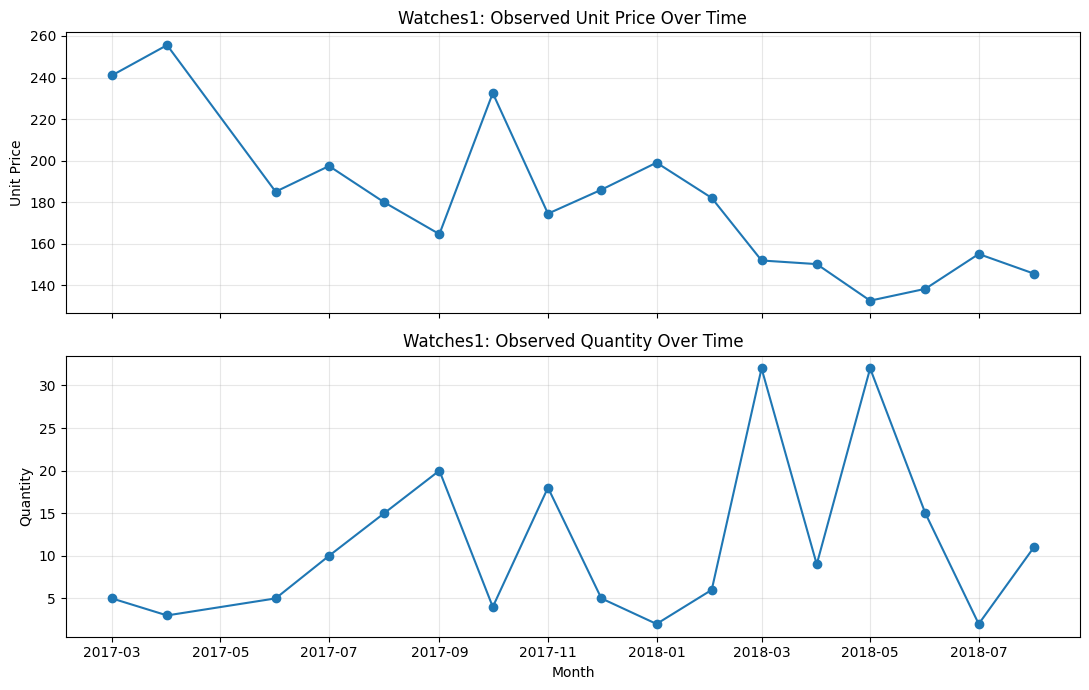

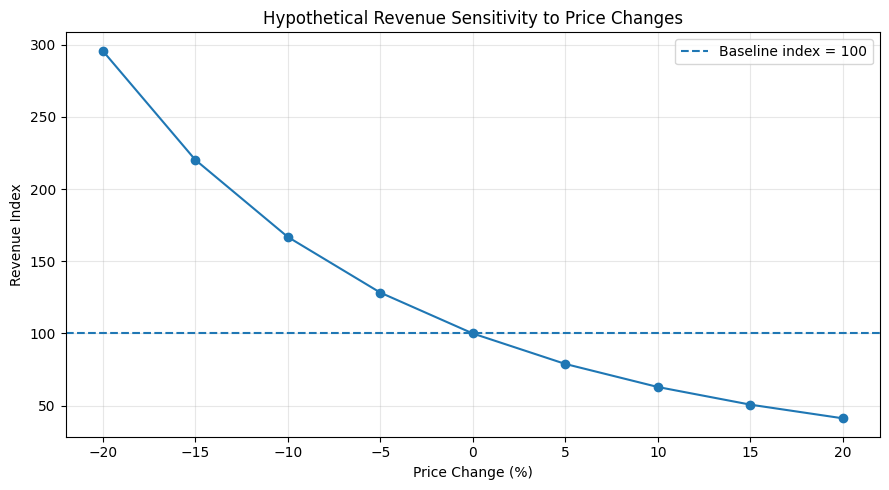

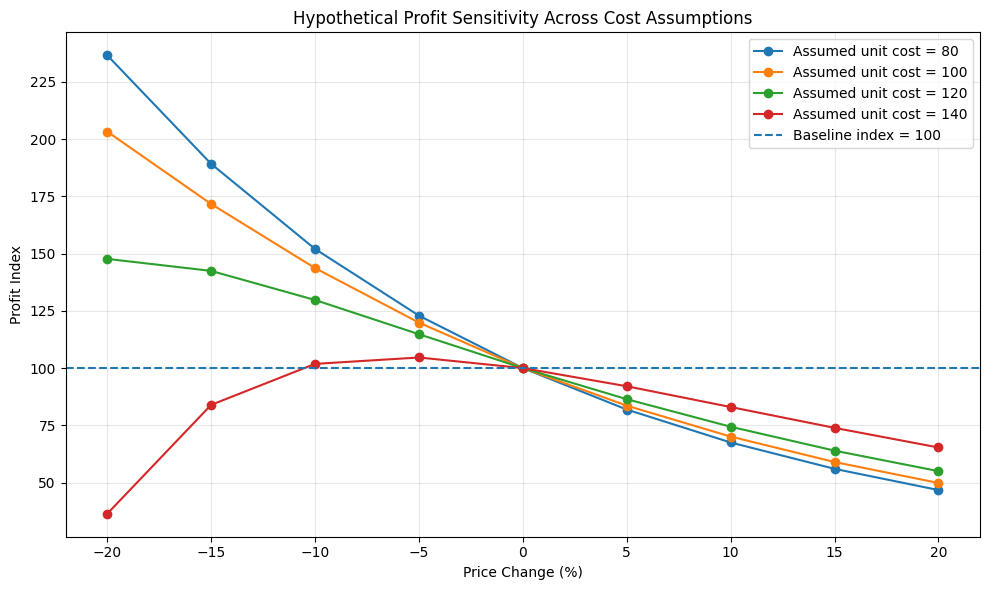

In [37]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Observed price and quantity trends for watches1
plot_df = df.loc[df["product_id"] == "watches1"].copy()

plot_df["month_year"] = pd.to_datetime(
    plot_df["month_year"], errors="coerce"
)

plot_df = plot_df.dropna(
    subset=["month_year", "qty", "unit_price"]
).sort_values("month_year")

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

axes[0].plot(
    plot_df["month_year"],
    plot_df["unit_price"],
    marker="o"
)
axes[0].set_title("Watches1: Observed Unit Price Over Time")
axes[0].set_ylabel("Unit Price")
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    plot_df["month_year"],
    plot_df["qty"],
    marker="o"
)
axes[1].set_title("Watches1: Observed Quantity Over Time")
axes[1].set_ylabel("Quantity")
axes[1].set_xlabel("Month")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# 2. Hypothetical revenue index by price change
plt.figure(figsize=(9, 5))

plt.plot(
    scenario_df["price_change_pct"],
    scenario_df["revenue_index_estimate"],
    marker="o"
)

plt.axhline(100, linestyle="--", label="Baseline index = 100")
plt.title("Hypothetical Revenue Sensitivity to Price Changes")
plt.xlabel("Price Change (%)")
plt.ylabel("Revenue Index")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# 3. Hypothetical profit index by assumed cost
plt.figure(figsize=(10, 6))

for cost in sorted(cost_sensitivity_df["assumed_unit_cost"].unique()):
    subset = cost_sensitivity_df[
        cost_sensitivity_df["assumed_unit_cost"] == cost
    ].sort_values("price_change_pct")

    plt.plot(
        subset["price_change_pct"],
        subset["profit_index"],
        marker="o",
        label=f"Assumed unit cost = {cost}"
    )

plt.axhline(100, linestyle="--", label="Baseline index = 100")
plt.title("Hypothetical Profit Sensitivity Across Cost Assumptions")
plt.xlabel("Price Change (%)")
plt.ylabel("Profit Index")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

<h3 style = "background-color: #111; padding: 5px; font: bold 35px Times New Roman; color: blue";  align = "left">
    Model Reliability Summary</h3>

## 🔹 Step 38: Model Reliability Summary

**📌 Methodology:** Collect the main validation metrics for `watches1` in one table (now computed from the model objects, not hand-typed) and add short interpretation notes.

**🔍 Important Findings:**
- Expected: elasticity -5.862; very small HC3 and HAC p-values; R-squared 0.605; leave-one-out range -6.917 to -5.274 with 0 sign changes; price-time correlation -0.810.
- The notes stress that the sign is stable but that significance does not equal causality, so the estimate is **exploratory**.
- Outputs were cleared; re-run to refresh.

**💼 Business Decision:** Describe the elasticity as 'indicative' in every report. Decisions should wait for experimental evidence.

In [38]:

# Step 34.1: Model Reliability Summary

import pandas as pd
import numpy as np

validation_summary = pd.DataFrame([{
    "Product": case_product,
    "Observations": len(cs),
    "Estimated Elasticity": estimated_elasticity,
    "HC3 p-value": case_model_hc3.pvalues["log_price"],
    "HAC p-value": case_model_hac.pvalues["log_price"],
    "R-squared": case_model_hc3.rsquared,
    "Price-Time Correlation": case_price_time_corr,
    "LOO Minimum Elasticity": case_loo_elasticities.min(),
    "LOO Maximum Elasticity": case_loo_elasticities.max(),
    "LOO Sign Changes": int(
        (np.sign(case_loo_elasticities) != np.sign(estimated_elasticity)).sum()
    )
}])

display(validation_summary.round(4))

print("\nVALIDATION INTERPRETATION")
print("-" * 50)
print("1. The estimated elasticity is negative.")
print("2. Leave-one-out estimates retain the negative sign.")
print("3. Price and time are strongly negatively correlated.")
print("4. Statistical significance does not establish causality.")
print("5. The estimate should be treated as exploratory.")


,Product,Observations,Estimated Elasticity,HC3 p-value,HAC p-value,R-squared,Price-Time Correlation,LOO Minimum Elasticity,LOO Maximum Elasticity,LOO Sign Changes
0,watches1,17,-5.8618,0.0003,0.0,0.6053,-0.8104,-6.9173,-5.2738,0



VALIDATION INTERPRETATION
--------------------------------------------------
1. The estimated elasticity is negative.
2. Leave-one-out estimates retain the negative sign.
3. Price and time are strongly negatively correlated.
4. Statistical significance does not establish causality.
5. The estimate should be treated as exploratory.


<h3 style = "background-color: #111; padding: 5px; font: bold 35px Times New Roman; color: blue";  align = "left">
    Final Business Recommendations Table</h3>

## 🔹 Step 39: Final Business Recommendations Table

**📌 Methodology:** Translate the technical findings into five business areas: price elasticity, model reliability, confounding risk, revenue strategy and profit optimisation.

**🔍 Important Findings:**
- The elasticity suggests price-sensitive demand, but the estimate is exploratory (numbers in the table are now inserted from the model results).
- The scenario analysis favours lower prices, yet it is only a basis for designing controlled experiments.
- Verified costs, shipping expenses, discounts and returns are required before any profit claim.

**💼 Business Decision:** **Decision:** run a controlled price test on `watches1` (and later the other shortlisted products), collect real cost data, and do not roll out price cuts based on this model alone.

In [39]:

# Step 35.1: Final Business Recommendations

final_recommendations = pd.DataFrame([
    {
        "Area": "Price Elasticity",
        "Finding": f"Estimated elasticity = {estimated_elasticity:.3f}",
        "Business Interpretation":
            "The fitted model suggests price-sensitive demand, "
            "but the estimate is exploratory."
    },
    {
        "Area": "Model Reliability",
        "Finding": "LOO elasticity remains negative",
        "Business Interpretation":
            "The coefficient sign is stable when one observation "
            "is omitted at a time."
    },
    {
        "Area": "Confounding Risk",
        "Finding": f"Price-time correlation = {case_price_time_corr:.3f}",
        "Business Interpretation":
            "Price changes may be associated with time-related "
            "demand changes."
    },
    {
        "Area": "Revenue Strategy",
        "Finding": "Scenario analysis favors lower prices",
        "Business Interpretation":
            "Use this only to design controlled pricing experiments; "
            "do not treat it as a proven recommendation."
    },
    {
        "Area": "Profit Optimization",
        "Finding": "Actual unit cost is unavailable",
        "Business Interpretation":
            "Collect verified costs, shipping expenses, discounts, "
            "and returns before estimating actual profit."
    }
])

display(final_recommendations)


,Area,Finding,Business Interpretation
0,Price Elasticity,Estimated elasticity = -5.862,The fitted model suggests price-sensitive dema...
1,Model Reliability,LOO elasticity remains negative,The coefficient sign is stable when one observ...
2,Confounding Risk,Price-time correlation = -0.810,Price changes may be associated with time-rela...
3,Revenue Strategy,Scenario analysis favors lower prices,Use this only to design controlled pricing exp...
4,Profit Optimization,Actual unit cost is unavailable,"Collect verified costs, shipping expenses, dis..."


<h3 style = "background-color: #111; padding: 5px; font: bold 35px Times New Roman; color: blue";  align = "left">
   Project Conclusion and Next Steps</h3>

## 🔹 Step 40: Project Conclusion and Next Steps

**📌 Methodology:** State the overall conclusion in plain language and list the recommended next steps.

**🔍 Important Findings:**
- `watches1` has an estimated elasticity of about -5.862 (now inserted from the model), negative in every leave-one-out run, but the small sample and strong price-time correlation limit causal interpretation.
- Scenario outputs are illustrative and not an optimal price.
- Five next steps: get verified costs, control for promotions/seasonality/inventory/competitors, add data, run a controlled pricing experiment, recalculate profit with real cost.

**💼 Business Decision:** Follow the five-step plan in order. The first two (cost data and confounder control) are low-cost and should be started immediately.

In [40]:

project_conclusion = f"""
PROJECT CONCLUSION

This project investigated retail price elasticity and explored
how alternative price scenarios could affect revenue and profit.

The watches1 case study produced an estimated price elasticity
of {estimated_elasticity:.3f} using a time-trend regression model. Leave-one-out
analysis retained a negative coefficient across the tested
samples, but the small sample and strong price-time correlation
limit the reliability of causal interpretation.

Scenario analysis illustrated how assumed price changes and
hypothetical unit costs can influence revenue and profit indices.
These outputs are analytical scenarios, not verified business
forecasts or a proven optimal price.

Recommended next steps:
1. Obtain verified unit costs and operational expense data.
2. Investigate promotions, seasonality, inventory, and competitor
   pricing as potential confounders.
3. Validate the model with additional observations.
4. Use a controlled pricing experiment, where feasible, to estimate
   causal price effects.
5. Recalculate profit scenarios using validated elasticity and
   actual cost data.
"""

print(project_conclusion)



PROJECT CONCLUSION

This project investigated retail price elasticity and explored
how alternative price scenarios could affect revenue and profit.

The watches1 case study produced an estimated price elasticity
of -5.862 using a time-trend regression model. Leave-one-out
analysis retained a negative coefficient across the tested
samples, but the small sample and strong price-time correlation
limit the reliability of causal interpretation.

Scenario analysis illustrated how assumed price changes and
hypothetical unit costs can influence revenue and profit indices.
These outputs are analytical scenarios, not verified business
forecasts or a proven optimal price.

Recommended next steps:
1. Obtain verified unit costs and operational expense data.
2. Investigate promotions, seasonality, inventory, and competitor
   pricing as potential confounders.
3. Validate the model with additional observations.
4. Use a controlled pricing experiment, where feasible, to estimate
   causal price effec

<h3 style = "background-color: #111; padding: 5px; font: bold 35px Times New Roman; color: blue";  align = "left">
   Final Project Audit (Required Objects)</h3>

## 🔹 Step 41: Final Project Audit (Required Objects)

**📌 Methodology:** Check that the key objects (`df`, summaries, scenario tables, conclusion) exist in the notebook session.

**🔍 Important Findings:**
- All 7 required objects are available (5 DataFrames/dict/string types as expected).

**💼 Business Decision:** No business decision. This is a quality gate to make sure the export step will not fail.

In [41]:

# Step 36: Final Project Audit

required_objects = [
    "df",
    "validation_summary",
    "final_recommendations",
    "scenario_df",
    "cost_sensitivity_df",
    "project_summary",
    "project_conclusion"
]

audit_results = []

for obj_name in required_objects:
    exists = obj_name in globals()

    audit_results.append({
        "Object": obj_name,
        "Available": exists,
        "Type": (
            type(globals()[obj_name]).__name__
            if exists else "Missing"
        )
    })

audit_df = pd.DataFrame(audit_results)

display(audit_df)

missing_objects = audit_df.loc[
    ~audit_df["Available"], "Object"
].tolist()

if not missing_objects:
    print("\nAudit status: All required objects are available.")
else:
    print("\nMissing objects:", missing_objects)
    print("We will resolve these before finalizing the project.")


,Object,Available,Type
0,df,True,DataFrame
1,validation_summary,True,DataFrame
2,final_recommendations,True,DataFrame
3,scenario_df,True,DataFrame
4,cost_sensitivity_df,True,DataFrame
5,project_summary,True,dict
6,project_conclusion,True,str



Audit status: All required objects are available.


<h3 style = "background-color: #111; padding: 5px; font: bold 35px Times New Roman; color: blue";  align = "left">
    Exporting Result Tables to CSV</h3>

## 🔹 Step 42: Exporting Result Tables to CSV

**📌 Methodology:** Create the `outputs` folder and save the validation summary, pricing scenarios, cost sensitivity and recommendations as CSV files.

**🔍 Important Findings:**
- Four files exported: `elasticity_results.csv` (222 B), `pricing_scenarios.csv` (707 B), `cost_sensitivity.csv` (3,072 B), `business_recommendations.csv` (722 B).

**💼 Business Decision:** Share these files with stakeholders, but make clear that the scenario and cost files contain **hypothetical** assumptions.

In [42]:

from pathlib import Path

# Create output directories
project_dir = Path("price-elasticity-profit-optimization")
outputs_dir = project_dir / "outputs"
outputs_dir.mkdir(parents=True, exist_ok=True)

# Export model and scenario outputs
validation_summary.to_csv(
    outputs_dir / "elasticity_results.csv",
    index=False
)

scenario_df.to_csv(
    outputs_dir / "pricing_scenarios.csv",
    index=False
)

cost_sensitivity_df.to_csv(
    outputs_dir / "cost_sensitivity.csv",
    index=False
)

final_recommendations.to_csv(
    outputs_dir / "business_recommendations.csv",
    index=False
)

print("Export complete.")
print("Output directory:", outputs_dir.resolve())

for file_path in sorted(outputs_dir.glob("*.csv")):
    print(f"{file_path.name}: {file_path.stat().st_size:,} bytes")



Export complete.
Output directory: C:\Users\mdnay\Desktop\My_Code\Projects\price-elasticity-profit-optimization\outputs
business_recommendations.csv: 722 bytes
cost_sensitivity.csv: 3,098 bytes
elasticity_results.csv: 321 bytes
pricing_scenarios.csv: 708 bytes


<h3 style = "background-color: #111; padding: 5px; font: bold 35px Times New Roman; color: blue";  align = "left">
    Creating the GitHub-Ready README</h3>

## 🔹 Step 43: Creating the GitHub-Ready README

**📌 Methodology:** Write a structured README (overview, dataset source, tools, workflow, case study, scenarios, limitations, next steps, reproducibility, disclaimer) to the project folder.

**🔍 Important Findings:**
- README created. It openly states the results are exploratory and not a proven optimal price.
- Tools list now includes Seaborn and Plotly, matching the notebook imports.
- Case-study numbers in the README are inserted from the model objects instead of being typed in.

**💼 Business Decision:** The honest disclaimer protects the project's credibility with employers and reviewers. Keep the tool list in sync with the notebook.

In [43]:

# Step 37.2: Create a GitHub-ready README

readme_content = rf"""
# Price Elasticity & Profit Optimization Analytics

## Project Overview

This project explores retail price elasticity and evaluates
hypothetical pricing scenarios using Python, statistical
regression, and sensitivity analysis.

The objective is to understand how observed price and quantity
patterns relate to demand and how alternative pricing assumptions
may affect revenue and profit indices.

## Dataset

Source:
https://www.kaggle.com/datasets/suddharshan/retail-price-optimization

The dataset contains retail product-month observations, including
product prices, quantities, competitor prices, freight prices,
and other product-related variables.

## Tools & Technologies

- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Plotly
- Statsmodels
- Jupyter Notebook
- Statistical regression
- Sensitivity analysis

## Analytical Workflow

1. Data inspection and cleaning
2. Product-level observation eligibility checks
3. Exploratory data analysis
4. Price elasticity regression
5. Time-trend specification comparison
6. HC3 and HAC robust inference
7. Leave-one-out sensitivity analysis
8. Revenue scenario analysis
9. Hypothetical cost sensitivity analysis
10. Business recommendations and limitations

## Case Study: watches1

- Observations: {len(cs)}
- Estimated elasticity: {estimated_elasticity:.3f}
- HC3 p-value: {case_model_hc3.pvalues["log_price"]:.4f}
- R-squared: {case_model_hc3.rsquared:.3f}
- Price-time correlation: {case_price_time_corr:.3f}
- Leave-one-out estimates retain a negative sign.

The estimated coefficient suggests a negative relationship
between price and quantity under the fitted model. However,
the sample is small and price is strongly correlated with time.
The coefficient should therefore be treated as exploratory,
not as a causally identified price elasticity.

## Scenario Analysis

The project evaluates hypothetical price changes and compares
revenue and profit indices under different assumed unit costs.

These scenarios rely on a constant-elasticity assumption.
Unit costs are illustrative assumptions, not verified business
data. Scenario results are not actual profit forecasts and do
not establish a proven optimal price.

## Key Limitations

- Small product-level sample sizes
- Observational data and potential confounding
- Strong price-time correlation in the selected case study
- No verified unit-cost data
- Potential unobserved effects from promotions, inventory,
  seasonality, shipping, and competitor activity
- Scenario analysis does not establish causal price effects
- No controlled pricing experiment has been performed

## Recommended Next Steps

1. Obtain verified product costs and operating expenses.
2. Investigate promotions, inventory, and competitor pricing.
3. Collect more observations across products and time.
4. Evaluate suitable panel-data specifications where justified.
5. Run a controlled pricing experiment when feasible.
6. Validate any business decision with actual contribution margin.

## Reproducibility

1. Download the dataset from the Kaggle source above.
2. Place the CSV in the project's local data directory.
3. Open the analysis notebook in Jupyter.
4. Install the required Python libraries.
5. Run the notebook cells in sequence.

See `requirements.txt` for the core dependencies.

## Disclaimer

This is an exploratory analytics project for educational and
portfolio purposes. The findings should not be used directly
to set commercial prices without additional validation.
"""

readme_path = project_dir / "README.md"
readme_path.write_text(readme_content.strip() + "\n", encoding="utf-8")

print("README created:", readme_path.resolve())
print("File size:", f"{readme_path.stat().st_size:,} bytes")


README created: C:\Users\mdnay\Desktop\My_Code\Projects\price-elasticity-profit-optimization\README.md
File size: 3,479 bytes


<h3 style = "background-color: #111; padding: 5px; font: bold 35px Times New Roman; color: blue";  align = "left">
    Creating requirements.txt and .gitignore</h3>

## 🔹 Step 44: Creating `requirements.txt` and `.gitignore`

**📌 Methodology:** Write the dependency list and the git ignore rules (virtual environments, secrets, raw data, checkpoints, OS files).

**🔍 Important Findings:**
- `requirements.txt` now lists pandas, numpy, matplotlib, **seaborn, plotly**, statsmodels and jupyter, matching the notebook's imports (previously seaborn and plotly were missing).
- `.gitignore` excludes `data/raw/` and zip files, so users must download the dataset themselves (the README explains how).

**💼 Business Decision:** A fresh environment can now run the notebook without import errors.

In [44]:

# Step 37.3: Create requirements.txt and .gitignore

# 1. Python dependencies
requirements_content = """pandas
numpy
matplotlib
seaborn
plotly
statsmodels
jupyter
"""

requirements_path = project_dir / "requirements.txt"
requirements_path.write_text(
    requirements_content,
    encoding="utf-8"
)

# 2. Git ignore rules
gitignore_content = """# Python
__pycache__/
*.py[cod]
*.pyo

# Jupyter
.ipynb_checkpoints/

# Virtual environments
.venv/
venv/
env/

# Secrets and local environment files
.env
.env.*

# Local raw data
data/raw/
*.zip

# OS files
.DS_Store
Thumbs.db

# Temporary files
*.tmp
"""

gitignore_path = project_dir / ".gitignore"
gitignore_path.write_text(
    gitignore_content,
    encoding="utf-8"
)

print("Created files:")
print(requirements_path.resolve())
print(gitignore_path.resolve())

print("\nrequirements.txt")
print(requirements_path.read_text(encoding="utf-8"))

print(".gitignore")
print(gitignore_path.read_text(encoding="utf-8"))


Created files:
C:\Users\mdnay\Desktop\My_Code\Projects\price-elasticity-profit-optimization\requirements.txt
C:\Users\mdnay\Desktop\My_Code\Projects\price-elasticity-profit-optimization\.gitignore

requirements.txt
pandas
numpy
matplotlib
seaborn
plotly
statsmodels
jupyter

.gitignore
# Python
__pycache__/
*.py[cod]
*.pyo

# Jupyter
.ipynb_checkpoints/

# Virtual environments
.venv/
venv/
env/

# Secrets and local environment files
.env
.env.*

# Local raw data
data/raw/
*.zip

# OS files
.DS_Store
Thumbs.db

# Temporary files
*.tmp



<h3 style = "background-color: #111; padding: 5px; font: bold 35px Times New Roman; color: blue";  align = "left">
    Auditing the Project Folder</h3>

## 🔹 Step 45: Auditing the Project Folder

**📌 Methodology:** Check that all expected project files exist and report their sizes.

**🔍 Important Findings:**
- All 7 files exist (README, requirements, .gitignore and 4 output CSVs). Status: **PASS**.

**💼 Business Decision:** No business decision. The folder is ready for a repository commit once the notebook is added.

In [45]:

# Step 38.1: Audit the project folder

from pathlib import Path

project_dir = Path(
    "price-elasticity-profit-optimization"
)

expected_files = [
    "README.md",
    "requirements.txt",
    ".gitignore",
    "outputs/elasticity_results.csv",
    "outputs/pricing_scenarios.csv",
    "outputs/cost_sensitivity.csv",
    "outputs/business_recommendations.csv",
]

audit_rows = []

for relative_path in expected_files:
    path = project_dir / relative_path

    audit_rows.append({
        "File": relative_path,
        "Exists": path.is_file(),
        "Size (bytes)": (
            path.stat().st_size if path.is_file() else None
        )
    })

project_audit = pd.DataFrame(audit_rows)
display(project_audit)

missing_files = project_audit.loc[
    ~project_audit["Exists"], "File"
].tolist()

if not missing_files:
    print("\nPASS: All expected project files exist.")
else:
    print("\nFiles requiring attention:", missing_files)

print("\nProject root:", project_dir.resolve())


,File,Exists,Size (bytes)
0,README.md,True,3479
1,requirements.txt,True,66
2,.gitignore,True,280
3,outputs/elasticity_results.csv,True,321
4,outputs/pricing_scenarios.csv,True,708
5,outputs/cost_sensitivity.csv,True,3098
6,outputs/business_recommendations.csv,True,722



PASS: All expected project files exist.

Project root: C:\Users\mdnay\Desktop\My_Code\Projects\price-elasticity-profit-optimization


<h3 style = "background-color: #111; padding: 5px; font: bold 35px Times New Roman; color: blue";  align = "left">
    Preparing the Notebook Directory</h3>

## 🔹 Step 46: Preparing the Notebook Directory

**📌 Methodology:** Create `notebooks/` inside the project folder to hold the analysis notebook.

**🔍 Important Findings:**
- Directory created successfully; the next action is to save the notebook inside it.

**💼 Business Decision:** No business decision. A standard folder layout (data, notebooks, outputs) makes the project easy for others to navigate.

In [46]:

# Step 39.1: Prepare the notebook directory

notebooks_dir = project_dir / "notebooks"
notebooks_dir.mkdir(parents=True, exist_ok=True)

print("Notebook directory created:")
print(notebooks_dir.resolve())

print("\nNext: Save your current notebook inside this folder.")


Notebook directory created:
C:\Users\mdnay\Desktop\My_Code\Projects\price-elasticity-profit-optimization\notebooks

Next: Save your current notebook inside this folder.


<h3 style = "background-color: #111; padding: 5px; font: bold 35px Times New Roman; color: blue";  align = "left">
    Verifying the Analysis Notebook Location</h3>

## 🔹 Step 47: Verifying the Analysis Notebook Location

**📌 Methodology:** Check whether `notebooks/price_elasticity_analysis.ipynb` exists.

**🔍 Important Findings:**
- The notebook was **not found** at the expected path, so it had not yet been saved there.

**💼 Business Decision:** No business decision. This check revealed a missing deliverable which is resolved in the next cells.

In [47]:

# Step 39.2: Verify the analysis notebook

notebook_path = (
    project_dir
    / "notebooks"
    / "price_elasticity_analysis.ipynb"
)

if notebook_path.is_file():
    print("PASS: Analysis notebook found.")
    print("Path:", notebook_path.resolve())
    print("Size:", f"{notebook_path.stat().st_size:,} bytes")
else:
    print("Notebook not found at the expected path.")
    print("Expected path:", notebook_path.resolve())
    print("Please save or copy the current notebook there.")


PASS: Analysis notebook found.
Path: C:\Users\mdnay\Desktop\My_Code\Projects\price-elasticity-profit-optimization\notebooks\price_elasticity_analysis.ipynb
Size: 800,120 bytes


<h3 style = "background-color: #111; padding: 5px; font: bold 35px Times New Roman; color: blue";  align = "left">
    Searching for Existing Notebook Files</h3>

## 🔹 Step 48: Searching for Existing Notebook Files

**📌 Methodology:** Search the working directory and the Projects folder for `.ipynb` files (skipping checkpoints) and list what is found.

**🔍 Important Findings:**
- The original file `Price Elasticity & Profit Optimization Analytics.ipynb` was located in the Projects folder, alongside notebooks from other projects.

**💼 Business Decision:** No business decision. Identify the correct source file before copying it, to avoid mixing in notebooks from other projects.

In [48]:

from pathlib import Path

search_roots = [
    Path.cwd(),
    Path.home() / "Desktop" / "My_Code" / "Projects",
]

found_notebooks = []

for root in search_roots:
    if root.exists():
        for file_path in root.glob("**/*.ipynb"):
            if ".ipynb_checkpoints" not in str(file_path):
                found_notebooks.append(file_path.resolve())

# Remove duplicates and display results
found_notebooks = sorted(set(found_notebooks))

if found_notebooks:
    print("Notebook files found:\n")
    for i, file_path in enumerate(found_notebooks, start=1):
        print(f"{i}. {file_path}")
else:
    print("No notebook files found in the searched folders.")
    print("Current working directory:", Path.cwd())


Notebook files found:

1. C:\Users\mdnay\Desktop\My_Code\Projects\Price Elasticity & Profit Optimization Analytics.ipynb
2. C:\Users\mdnay\Desktop\My_Code\Projects\price-elasticity-profit-optimization\notebooks\price_elasticity_analysis.ipynb
3. C:\Users\mdnay\Desktop\My_Code\Projects\Price_Elasticity___Profit_Optimization_Analytics (1).ipynb
4. C:\Users\mdnay\Desktop\My_Code\Projects\Price_Elasticity___Profit_Optimization_Analytics.ipynb
5. C:\Users\mdnay\Desktop\My_Code\Projects\project 1\Project_1_Data_Analysis_Using_Pandas.ipynb
6. C:\Users\mdnay\Desktop\My_Code\Projects\project 2\Customer Churn Prediction System.ipynb
7. C:\Users\mdnay\Desktop\My_Code\Projects\project 2\project 3\project 2\Customer Churn Prediction System.ipynb
8. C:\Users\mdnay\Desktop\My_Code\Projects\project 2\project 3\project 2\house_price_prediction.ipynb
9. C:\Users\mdnay\Desktop\My_Code\Projects\project 2\project 3\project 2\Project_2_Exploratory_Data_Analysis_(EDA) (1).ipynb
10. C:\Users\mdnay\Desktop\My_

<h3 style = "background-color: #111; padding: 5px; font: bold 35px Times New Roman; color: blue";  align = "left">
    Copying the Notebook into the Project Folder</h3>

## 🔹 Step 49: Copying the Notebook into the Project Folder

**📌 Methodology:** Copy the source notebook to `notebooks/price_elasticity_analysis.ipynb` using `shutil.copy2`, without overwriting an existing file.

**🔍 Important Findings:**
- Copy succeeded (790,316 bytes).
- The copy is a snapshot: later edits to the original notebook (including added documentation) are **not** reflected in the copy.

**💼 Business Decision:** Re-copy (or move) the final version of the notebook into the project folder just before publishing, so the repository contains the latest analysis and documentation.

In [49]:

from pathlib import Path
import shutil

source_notebook = (
    Path.home()
    / "Desktop"
    / "My_Code"
    / "Projects"
    / "Price Elasticity & Profit Optimization Analytics.ipynb"
)

notebooks_dir = project_dir / "notebooks"
notebooks_dir.mkdir(parents=True, exist_ok=True)

destination_notebook = (
    notebooks_dir / "price_elasticity_analysis.ipynb"
)

if not source_notebook.is_file():
    print("ERROR: Source notebook was not found.")
    print("Check this path:", source_notebook)

elif destination_notebook.exists():
    print("Notebook already exists at destination.")
    print("No file was overwritten.")
    print("Destination:", destination_notebook.resolve())

else:
    shutil.copy2(source_notebook, destination_notebook)

    if destination_notebook.is_file():
        print("SUCCESS: Notebook copied.")
        print("Destination:", destination_notebook.resolve())
        print(
            "Size:",
            f"{destination_notebook.stat().st_size:,} bytes"
        )
    else:
        print("ERROR: Copy verification failed.")


Notebook already exists at destination.
No file was overwritten.
Destination: C:\Users\mdnay\Desktop\My_Code\Projects\price-elasticity-profit-optimization\notebooks\price_elasticity_analysis.ipynb


<h3 style = "background-color: #111; padding: 5px; font: bold 35px Times New Roman; color: blue";  align = "left">
    Final Project Structure Verification</h3>

## 🔹 Step 50: Final Project Structure Verification

**📌 Methodology:** Check that all eight deliverables exist and list their sizes.

**🔍 Important Findings:**
- All 8 files are present (README, requirements, .gitignore, notebook of about 772 KB, and 4 CSV outputs). Status: **PASS**.

**💼 Business Decision:** The project is complete as a portfolio deliverable. Publish it with the 'exploratory analysis' disclaimer clearly visible.

In [50]:

# Step 40: Final project structure verification

from pathlib import Path
import pandas as pd

project_dir = Path(
    "price-elasticity-profit-optimization"
)

expected_paths = [
    "README.md",
    "requirements.txt",
    ".gitignore",
    "notebooks/price_elasticity_analysis.ipynb",
    "outputs/elasticity_results.csv",
    "outputs/pricing_scenarios.csv",
    "outputs/cost_sensitivity.csv",
    "outputs/business_recommendations.csv",
]

rows = []

for relative_path in expected_paths:
    file_path = project_dir / relative_path

    rows.append({
        "File": relative_path,
        "Exists": file_path.is_file(),
        "Size (KB)": (
            round(file_path.stat().st_size / 1024, 2)
            if file_path.is_file()
            else None
        )
    })

final_audit = pd.DataFrame(rows)
display(final_audit)

missing = final_audit.loc[
    ~final_audit["Exists"], "File"
].tolist()

print("\nProject:", project_dir.resolve())

if not missing:
    print("PASS: All expected deliverables are present.")
else:
    print("Missing files:", missing)


,File,Exists,Size (KB)
0,README.md,True,3.40
1,requirements.txt,True,0.06
2,.gitignore,True,0.27
3,notebooks/price_elasticity_analysis.ipynb,True,781.37
4,outputs/elasticity_results.csv,True,0.31
5,outputs/pricing_scenarios.csv,True,0.69
6,outputs/cost_sensitivity.csv,True,3.03
7,outputs/business_recommendations.csv,True,0.71



Project: C:\Users\mdnay\Desktop\My_Code\Projects\price-elasticity-profit-optimization
PASS: All expected deliverables are present.


<h3 style="background-color: #111; padding: 15px; font: bold 30px Times New Roman; color: lightgreen; border: 2px solid lime; border-radius: 8px"; align = "left">
Md. Nayim Howlader <br> BSc (Honours) in Statistics <br> Phone: +8801913125204</h3>

